(mmm_mu_effects_intro)=
# Introduction to Mu Effects: Channel Interactions

Marketing teams often expect some channels to work better together. For example, a TV campaign can raise brand awareness, and the same search budget then brings more sales in the weeks with TV. We call this a *synergy* between the two channels.

An additive media mix model (MMM) with only main effects and the identity link cannot represent a synergy. In this model, the effect of each channel does not depend on the spend of the other channels.

In this notebook we add a channel interaction to the additive {class}`~pymc_marketing.mmm.mmm.MMM` with a custom **mu effect**, a term that we add to the linear predictor $\mu$ of the model. We show how to write the effect, and how the budget optimizer sees the interaction while it changes only the spend of the channels that we can buy.

We use the data of {ref}`mmm_multiplicative` to compare our results with the models of that notebook. The data is synthetic, and the process that generated it has *no* interaction between the channels. We first build the interaction effect, and then we check what it estimates and how it changes the budget plan when there is no synergy to find.

Here is the outline:

1. **Channel Interactions**: what an interaction is, and how it differs from the dependence that the log link creates.
2. **Mu Effects**: what a mu effect is, and when it is useful.
3. **The Product Column Problem**: why a product column in the data does not work for budget optimization.
4. **Load Data** and **Exploratory Data Analysis**: the spend of the two channels and their product.
5. **Additive Model**: the additive model of {ref}`mmm_multiplicative`.
6. **Interaction Mu Effect**: the methods of a mu effect, and the code and priors of the interaction effect.
7. **Interaction Model**: the additive model plus the interaction effect.
8. **Return on Ad Spend (ROAS)**: the ROAS of both models with the `mmm.incrementality` module.
9. **Budget Optimization**: the plans of both models, with the setup of {ref}`mmm_multiplicative`.
10. **Value of the Interaction**: what the interaction adds on this data.
11. **Conclusion**: what we learned, and when to use an interaction effect.

```{note}
See {ref}`mmm_example` for the data and the process that generated it, and {ref}`mmm_multiplicative` for the log model on the same data. For other custom mu effects, see {ref}`mmm_funnel_mueffect` and {ref}`mmm_halo`.
```

## Channel Interactions

Two channels interact when the return of one channel depends on the spend of the other. In the example above, search sells more per unit of spend in the weeks with TV.

We describe the model with a causal graph and a structural function (see the [CausalPy guide to structural causal models](https://causalpy.readthedocs.io/en/latest/knowledgebase/structural_causal_models.html)). The graph shows the parents of sales, which are the variables that affect sales, and the function shows how they combine. Here is the graph of our example:

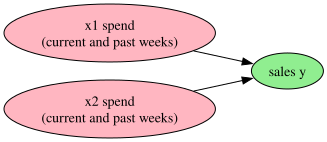

In [1]:
import graphviz as gr

# Simplified causal graph: the spends of the two channels are the parents of sales
dag = gr.Digraph()
dag.attr(rankdir="LR")
dag.node(
    "x1", "x1 spend\n(current and past weeks)", style="filled", fillcolor="lightpink"
)
dag.node(
    "x2", "x2 spend\n(current and past weeks)", style="filled", fillcolor="lightpink"
)
dag.node("y", "sales y", style="filled", fillcolor="lightgreen")
dag.edge("x1", "y")
dag.edge("x2", "y")
dag

This graph is a simplified view of the channel-to-sales mechanism. Each spend node stands for the spend history of the channel, because the adstock carries past spend into later weeks. The graph does not draw these lags, or the other parents of sales (trend, seasonality, events and noise).

The graph also leaves out common causes of spend and sales, such as budgets planned around seasonal demand. It does not show that we can estimate the channel effects from real data.

The same graph fits a sales function with or without an interaction. Take one week without carryover. The regression formula `y ~ x1 + x2 + x1:x2` has a product term:

$$
y = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \beta_{12} x_1 x_2 + \varepsilon,
$$

and the marginal return of `x1` is $\beta_1 + \beta_{12} x_2$, which depends on `x2`.

This model is linear in its coefficients and still has an interaction. The interaction is part of the sales function, so it needs no new node in the graph and no product column in the data.

In this notebook we keep the identity link and the main effects of the MMM, and we add one term for each group of channels that we expect to interact. The input of this term is the product of the same-week spend of these channels:

$$
\mu_t = b_t + \sum_{c} f_c(x_c)_t + \sum_{k} g_k\Big(\prod_{c \in S_k} x_c\Big)_t
$$

where:

- $\mu_t$ is the expected sales in week $t$, divided by the largest weekly sales.
- $b_t$ is the baseline: the intercept, the controls and the yearly seasonality.
- $x_c$ is the weekly spend of channel $c$, divided by its largest value in the training data.
- $f_c$ is the media term of channel $c$, $f_c(z)_t = \beta \, L_\lambda\big(A_\alpha(z)\big)_t$. It applies the geometric adstock $A_\alpha$, then the logistic saturation $L_\lambda$, and multiplies the result by the coefficient $\beta$.
- $S_k$ is the group of channels of interaction $k$, with two or more channels. For example, $S_1 = \{1, 2\}$ for `x1` and `x2`.
- $g_k$ is the interaction term. It has the same form as a media term, with its own $\alpha$, $\lambda$ and $\beta$.

Note that the product comes before the adstock and the saturation, so the term is not the product of the channel terms $f_1$ and $f_2$. Without the adstock and the saturation, it reduces to $\beta \, x_1 x_2$, the product term of the regression above.

The product is zero in every week in which one of the channels of $S_k$ has no spend. The term therefore gets input only from the weeks in which all its channels are active.

With $S_1 = \{1, 2\}$, more spend on `x2` raises the marginal return of `x1`, and the other way around, as long as the interaction term is far from saturation. An interaction term can therefore change the split of the budget.

The log link of {ref}`mmm_multiplicative` creates a different kind of dependence. Its sales response is $s \, e^{\mu_t}$, where $s$ is the target scale and $\mu_t$ has the main effects only. For a flat plan, once the adstock has settled, the marginal return of `x1` in week $t$ is $s \, e^{\mu_t} f_1'(x_1)$, which depends on `x2` through the factor $e^{\mu_t}$.

The link and the main effects impose this dependence on the sales scale, and the model has no coefficient for it. The factor $e^{\mu_t}$ is the same for all channels in a week, so it cancels in the ratio of their marginal returns.

The link alone therefore hardly changes how the optimizer splits the budget.

## Mu Effects

A mu effect is a component that adds a term to the linear predictor $\mu$ of the MMM. We pass it to the model with {meth}`~pymc_marketing.mmm.mmm.MMM.add_mu_effect`.

The module {mod}`pymc_marketing.mmm.additive_effect` has built-in mu effects for trends, Fourier seasonality and events, and `MediaMuEffect` and `ControlMuEffect` for media and control data with other dims. The documentation also has custom mu effects for funnel mediators ({ref}`mmm_funnel_mueffect` and {ref}`mmm_case_study2`), halo effects ({ref}`mmm_halo`), spillovers between products ({ref}`mmm_pareto_optimization`) and transformed controls ({ref}`mmm_gam_options`).

When is a mu effect useful? Use one when you need a term that adds to $\mu$, but that the channels, controls and seasonality of the MMM cannot express. A channel interaction is such a term, and the named deterministics of the effect let us inspect and report it.

## The Product Column Problem

The interaction term above has the form of a media term whose input is the product of the spends. The simplest way to add it is a column `x1x2 = x1 * x2` in the data, which we pass to the MMM as a third channel. The model then fits a media term for the product, as in the equation above.

This works for fitting. The problem is that the rest of the workflow treats `x1x2` as a channel that we can buy:

- **Budget optimization**: The optimizer decides the spend of every channel. It gives budget to `x1x2`, and nothing ties this budget to the spend on `x1` and `x2`. If we exclude `x1x2` from the optimization, its spend stays at zero over the plan, and the interaction drops out.
- **ROAS**: The `mmm.incrementality` module reports a spend and a ROAS for `x1x2`.

The product is a function of the two spends, so we cannot set it on its own. The multiplication itself is fine. The problem is the product column, which lets the optimizer set this derived feature as if it were a channel.

A mu effect solves this. It computes the product inside the model from the spend of `x1` and `x2`. When the optimizer changes the spend of `x1` or `x2`, the product follows, and `x1` and `x2` stay the only channels.

## Prepare Notebook

We load the necessary libraries and set the notebook's configuration.

In [2]:
import warnings
from itertools import combinations
from typing import Annotated, Any

import arviz as az
import arviz_plots as azp
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import pymc as pm
import pymc.dims as pmd
import xarray as xr
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from pydantic import Field, InstanceOf, field_validator
from pymc_extras.prior import Prior
from pytensor.xtensor import as_xtensor, where
from scipy.optimize import minimize_scalar

from pymc_marketing.mmm import GeometricAdstock, LogisticSaturation
from pymc_marketing.mmm.additive_effect import IncrementalitySpec, MuEffect
from pymc_marketing.mmm.budget_optimizer import BudgetOptimizer
from pymc_marketing.mmm.components.adstock import AdstockTransformation
from pymc_marketing.mmm.components.saturation import SaturationTransformation
from pymc_marketing.mmm.mmm import MMM
from pymc_marketing.serialization import serialization

# Raised inside `MMM.fit` by a deprecated PyMC argument. It does not change the results.
warnings.filterwarnings(
    "ignore", message="`merge_dataset` is deprecated", category=FutureWarning
)

az.style.use("arviz-darkgrid")
plt.rcParams["figure.figsize"] = [12, 7]
plt.rcParams["figure.dpi"] = 100

%config InlineBackend.figure_format = "retina"

seed = sum(map(ord, "mmm_mu_effects_intro"))
rng = np.random.default_rng(seed=seed)

## Load Data

We use the synthetic weekly data of {ref}`mmm_example`, as {ref}`mmm_multiplicative` does. It has two media channels, `x1` and `x2`, the event indicators `event_1` and `event_2`, and the sales `y`. We add the integer trend `t`, as in the additive model of {ref}`mmm_multiplicative`.

In [3]:
url = "https://raw.githubusercontent.com/pymc-labs/pymc-marketing/main/data/mmm_example.csv"
data = pd.read_csv(url, parse_dates=["date_week"])

# Integer trend 0, 1, ..., n - 1
data["t"] = range(len(data))

CHANNELS = ["x1", "x2"]
CONTROLS = ["event_1", "event_2", "t"]

# Model inputs: the date, the channels and the controls, shape (date, 6)
X = data[["date_week", *CHANNELS, *CONTROLS]]
y = data["y"]

## Exploratory Data Analysis

Let's look at the spend of the two channels and at their product, the input of the interaction term. Both channels are already on a scale from $0$ to $1$. See {ref}`mmm_multiplicative` for a plot of the sales.

We shade the weeks in which `x2` has spend, in this plot and in a later one. The helper below draws this shading.

In [4]:
# True in the weeks with spend on x2, shape (date,)
x2_active = data["x2"] > 0


def shade_x2_weeks(ax: plt.Axes) -> Patch:
    """Shade the weeks with spend on x2 and return a legend handle for the shading."""
    for date in data.loc[x2_active, "date_week"]:
        ax.axvspan(
            date - pd.Timedelta(days=3.5),
            date + pd.Timedelta(days=3.5),
            color="C1",
            alpha=0.15,
            linewidth=0,
        )

    return Patch(
        color="C1",
        alpha=0.15,
        label=f"weeks with spend on x2 ({x2_active.sum()} of {len(data)})",
    )

Now we plot the spend and the product.

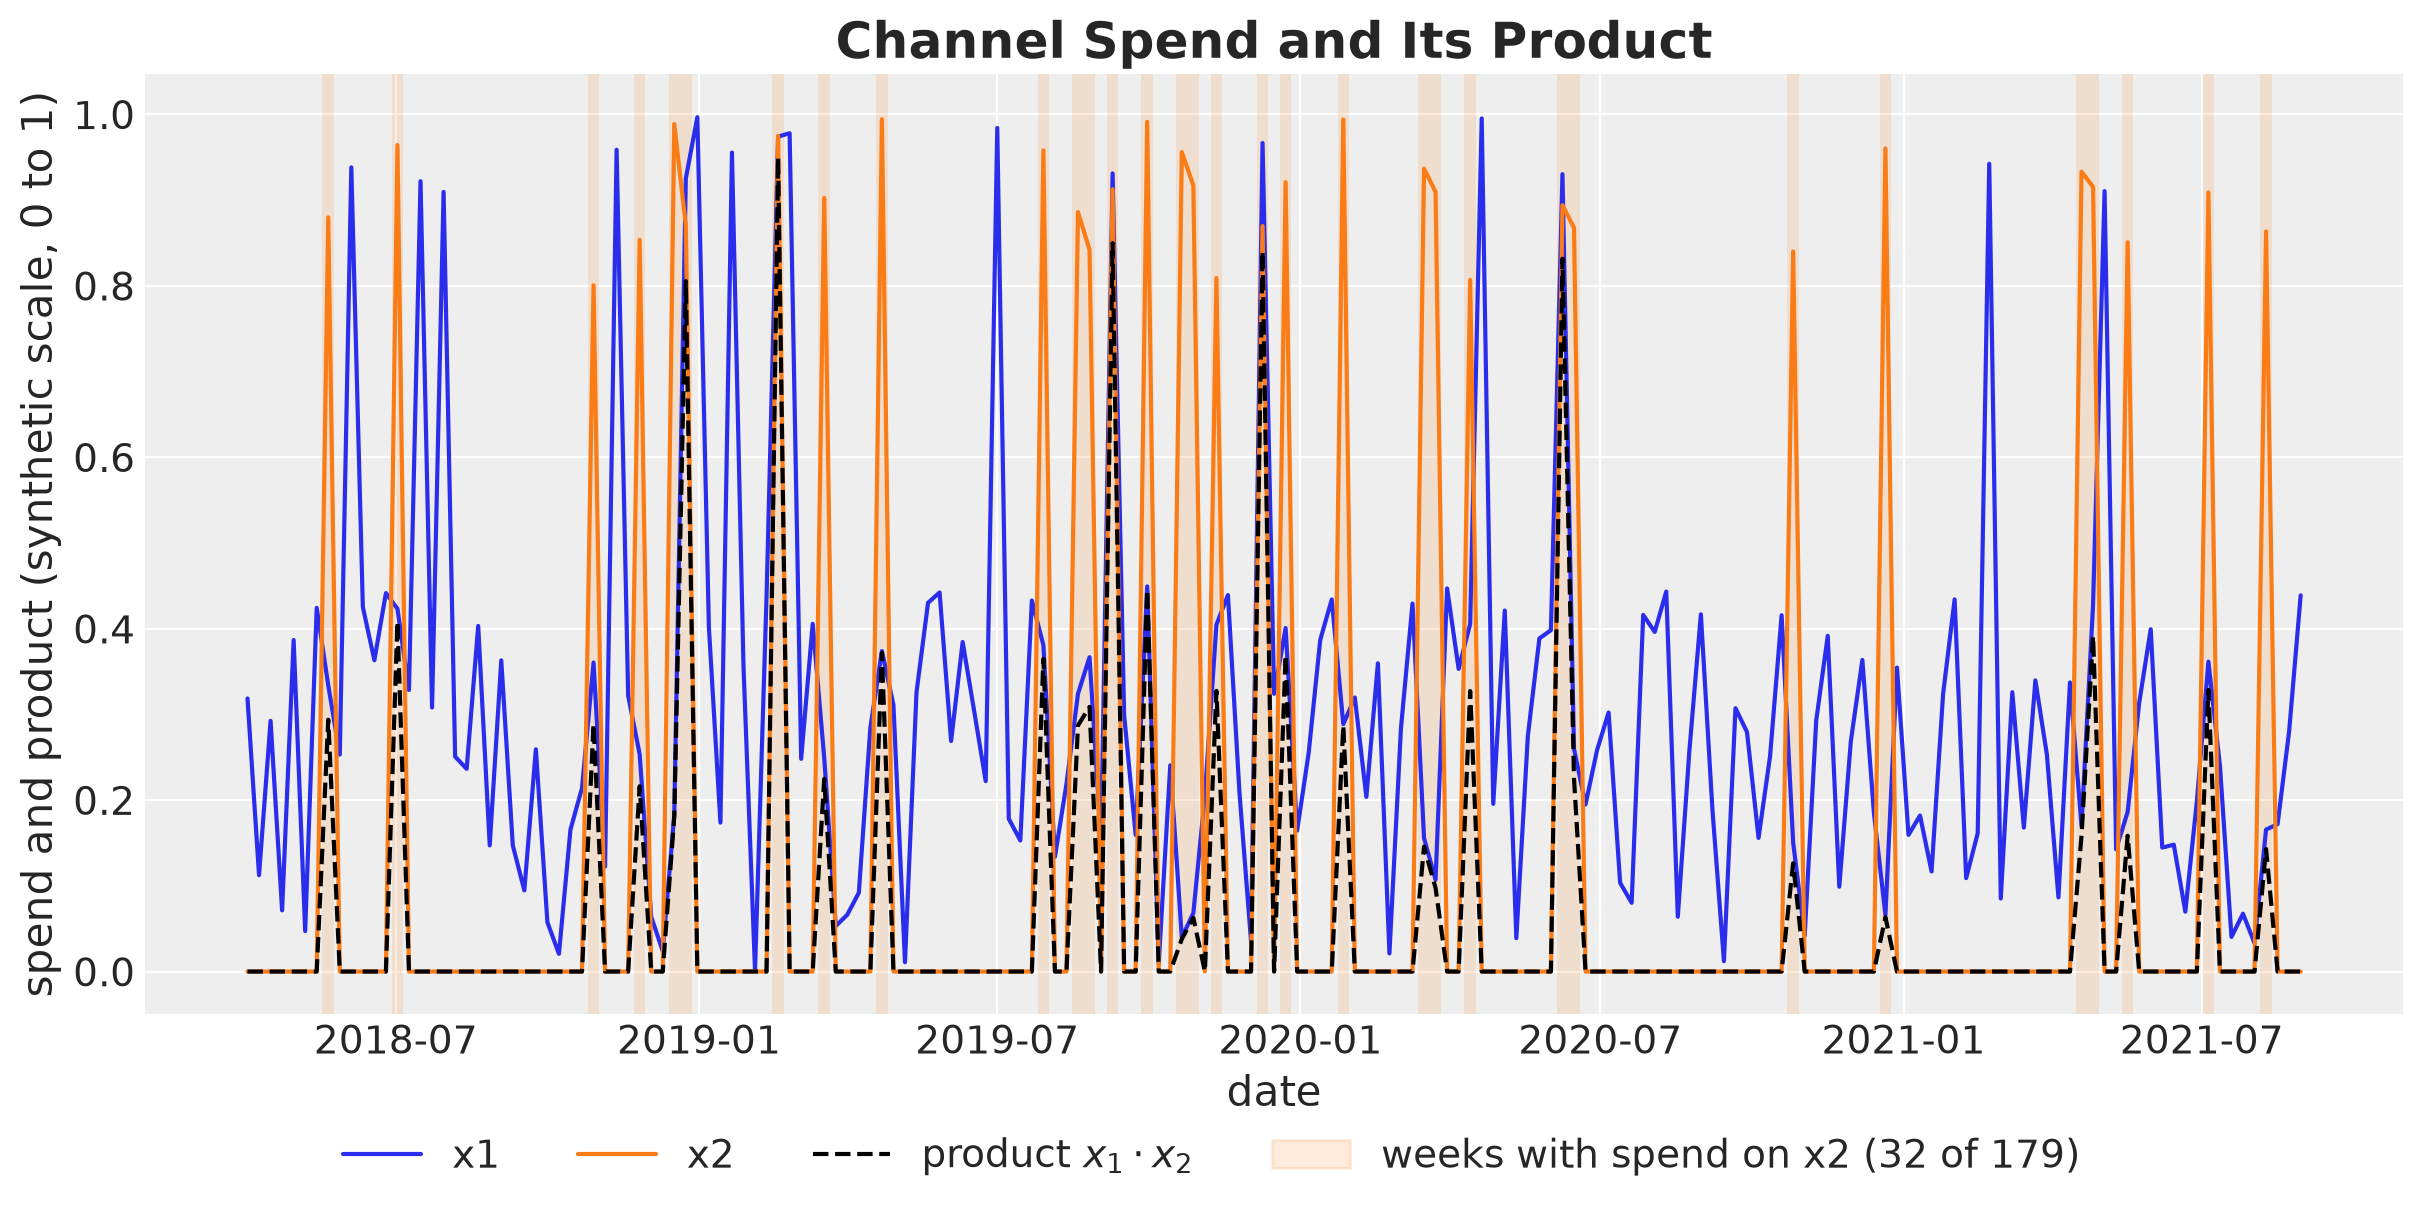

In [5]:
fig, ax = plt.subplots(figsize=(12, 6), layout="constrained")
x2_handle = shade_x2_weeks(ax)
ax.plot(data["date_week"], data["x1"], color="C0", label="x1")
ax.plot(data["date_week"], data["x2"], color="C1", label="x2")
ax.plot(
    data["date_week"],
    data["x1"] * data["x2"],
    color="black",
    linestyle="--",
    label=r"product $x_1 \cdot x_2$",
)
fig.legend(
    handles=[*ax.get_legend_handles_labels()[0], x2_handle],
    loc="outside lower center",
    ncols=4,
)
ax.set(xlabel="date", ylabel="spend and product (synthetic scale, 0 to 1)")
ax.set_title("Channel Spend and Its Product", fontsize=18, fontweight="bold");

`x1` has spend in every week. `x2` has spend in only $32$ of the $179$ weeks, in short bursts at a high level, between about $0.8$ and $1$.

The product follows `x1` in these bursts and is zero in all other weeks. It is an input of the interaction term, and we cannot buy it.

Here is an important observation: the adstock of the interaction term carries this input into up to $7$ following weeks, with weights that fall by a factor $\alpha$ each week. These carryover weeks also inform the coefficient and the carryover of the interaction.

Only the weeks far from any burst of `x2` have no interaction input. They inform the main effect of `x1` without the interaction.

In the $32$ weeks the product is between about $0.8$ and $1$ times `x1`. The interaction term then looks like a second `x1` term, and the data has little independent variation to tell the two terms apart. Recall that the true process has no interaction.

## Additive Model

We start with the additive model of {ref}`mmm_multiplicative`, without interaction. It has the channels `x1` and `x2`, the controls `event_1`, `event_2` and `t`, and yearly seasonality of order two.

We reuse the priors of that notebook. The prior scale of the coefficient $\beta$ of each channel is proportional to the share of the channel in the total spend.

In [6]:
# Share of the total spend of each channel, shape (channel,)
spend_share = data[CHANNELS].sum() / data[CHANNELS].sum().sum()

# Prior scale of the channel coefficients: the number of channels times the spend share, shape (channel,)
prior_sigma = xr.DataArray(
    len(CHANNELS) * spend_share.to_numpy(),
    dims="channel",
    coords={"channel": CHANNELS},
)

model_config = {
    "intercept": Prior("Normal", mu=0.5, sigma=0.2),
    "saturation_beta": Prior("HalfNormal", sigma=prior_sigma, dims="channel"),
    "gamma_control": Prior("Normal", mu=0, sigma=0.05, dims="control"),
    "gamma_fourier": Prior("Laplace", mu=0, b=0.2, dims="fourier_mode"),
    "likelihood": Prior("Normal", sigma=Prior("HalfNormal", sigma=6), dims="date"),
}

We build both models of this notebook from this specification, so we wrap it in a helper.

In [7]:
def make_mmm() -> MMM:
    """Return the additive MMM of the log model notebook."""
    return MMM(
        model_config=model_config,
        target_column="y",
        date_column="date_week",
        channel_columns=CHANNELS,
        control_columns=CONTROLS,
        yearly_seasonality=2,
        adstock=GeometricAdstock(l_max=8),
        saturation=LogisticSaturation(),
    )

Now we fit the additive model. We draw $1{,}500$ samples per chain after $1{,}500$ tuning steps.

In [8]:
fit_kwargs = {
    "chains": 4,
    "tune": 1_500,
    "draws": 1_500,
    "target_accept": 0.85,
    "nuts_sampler": "nutpie",
    "random_seed": rng,
    "progressbar": False,
}

mmm_additive = make_mmm()
_ = mmm_additive.fit(X, y, **fit_kwargs)

NUTS[nutpie]: [adstock_alpha, saturation_lam, saturation_beta, gamma_fourier, gamma_control, intercept_contribution, y_sigma]


Output()

Before looking into the results, let's check some diagnostics with `az.diagnose`: divergences, energy (E-BFMI), effective sample size (ESS) and $\hat{R}$ of the parameters.

In [9]:
_ = az.diagnose(
    mmm_additive.idata,
    var_names=[variable.name for variable in mmm_additive.model.free_RVs],
)

Divergences
No divergent transitions found.

E-BFMI
E-BFMI satisfactory for all chains.

ESS
Effective sample size satisfactory for all parameters.

R-hat
R-hat values satisfactory for all parameters.

Processing complete, no problems detected.


The additive model passes every check. See {ref}`mmm_multiplicative` for its posterior predictive check.

Let's look at the structure of the additive model.

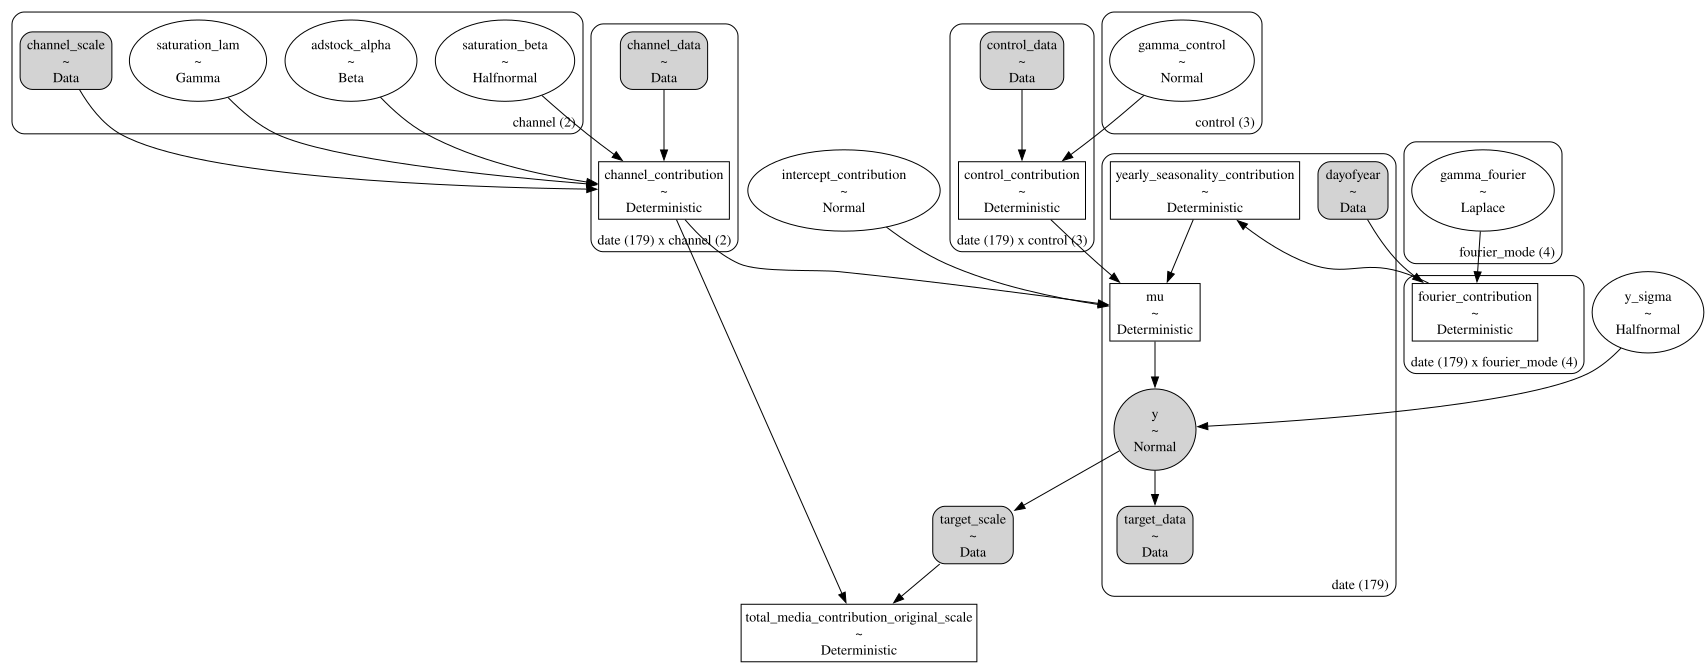

In [10]:
mmm_additive.model.to_graphviz()

This is a computation graph. Next to the data and the parameters, it shows named steps of the sales function, such as `channel_contribution`. These steps follow from the spend, and they are not extra causes in the causal graph of the Channel Interactions section.

The spend in `channel_data` goes through the adstock and saturation parameters into `channel_contribution`, which adds to `mu` together with the intercept, the controls and the seasonality. Note that `total_media_contribution_original_scale`, the default objective of the budget optimizer, reads `channel_contribution` only.

## Interaction Mu Effect

Next, we write the interaction effect. We start with the methods that every mu effect has, and then we write the class and choose its priors.

### Implementation

A mu effect is a subclass of {class}`~pymc_marketing.mmm.additive_effect.MuEffect`. `MuEffect` is a Pydantic model, so we declare the inputs of an effect as typed class attributes instead of writing an `__init__`. It is also an abstract class with three methods that every mu effect implements:

```python
class MyEffect(MuEffect):
    prefix: str

    def create_data(self, mmm) -> None: ...

    def create_effect(self, mmm): ...

    def set_data(self, mmm, model, X) -> None: ...
```

The MMM calls these methods at set steps of its workflow. The table below lists them, together with the optional methods that the interaction effect needs.

| Method | When the MMM calls it | What it does |
|---|---|---|
| `create_data(mmm)` | In `build_model`, after it registers and scales the channel and target data, and before the media terms | Registers the data and the coordinates of the effect in `mmm.model`. |
| `create_effect(mmm)` | In `build_model`, after the channel, control and seasonality terms | Returns the term that the model adds to $\mu$, with dims `("date", *mmm.dims)`, on the scale of the scaled target. |
| `set_data(mmm, model, X)` | In `sample_posterior_predictive`, and when the MMM builds the model of the budget optimizer | Updates the data of the effect, for example for new dates. |
| `incrementality_spec()` | In `mmm.incrementality`, and when the budget optimizer sizes its window | Lets `mmm.incrementality` include the effect when it sets the spend of a channel to zero, and declares extra carryover weeks of the effect. |
| `to_dict()` and `from_dict()` | In `sample_prior_predictive`, at the end of `fit`, and in `MMM.load` | Serialize the effect, if a field is not a Pydantic type. |
| `contribution_var_name` | In the contribution decomposition, in `mmm.incrementality` and in the checks of `MMM.budget_optimizer` | Names the deterministic with dims `("date", *mmm.dims)` that holds the term. The default is `{prefix}_effect_contribution`. |

A channel interaction needs four more things:

1. **Read the spend of the model.** The effect builds the product from `mmm.channel_data_scaled`, the scaled spend that the model holds. A new `pm.Data` variable with the product would be a fixed input, as the product column is. The same holds for a `MediaMuEffect` on a product column, because it reads its own `pm.Data`.
2. **Opt in to incrementality.** The term depends on the spend, so `incrementality_spec` returns an `IncrementalitySpec`. Without it, `mmm.incrementality` raises an error, so the interaction cannot drop out of the incremental sales without notice. Declare `additional_carryover_lags` only if the adstock of the interaction is longer than the adstock of the channels (here both have `l_max=8`).
3. **Serialize the transformations.** The adstock and the saturation are not Pydantic types. Without `to_dict` and `from_dict`, `sample_prior_predictive` and `fit` raise a `PydanticSerializationError` when they store the effect with the samples. To load a saved model with `MMM.load` in a new session, define the class first.
4. **Optimize the full response.** The default objective of the budget optimizer does not include mu effects (see the Budget Optimization section).

The main step of the effect is the product of the spend of the channels of each interaction. We describe the interactions with a membership mask, with one row per interaction and one column per channel, and we build it with a helper.

In [11]:
def membership_mask(
    interactions: list[tuple[str, ...]], channels: list[str], dim: str = "interaction"
) -> xr.DataArray:
    """Return a boolean mask with dims (dim, channel), True where the channel is in the interaction."""
    return xr.DataArray(
        [
            [channel in interaction for channel in channels]
            for interaction in interactions
        ],
        dims=(dim, "channel"),
        coords={
            dim: [":".join(interaction) for interaction in interactions],
            "channel": channels,
        },
    )

Let's see how the mask works for one week with three channels, two pairs and one triple. We keep the spend of the channels in an interaction, set the other entries to $1$, and multiply along the channels.

In [12]:
example_channels = ["x1", "x2", "x3"]
example_mask = membership_mask(
    [("x1", "x2"), ("x2", "x3"), ("x1", "x2", "x3")], example_channels
)

# Spend of one week, dims (channel,)
example_spend = xr.DataArray(
    [0.5, 0.4, 0.2], dims="channel", coords={"channel": example_channels}
)

# Product over the channels, with 1 for the channels outside each interaction, dims (interaction,)
example_product = xr.where(example_mask, example_spend, 1.0).prod(dim="channel")

example_mask.to_pandas().assign(product=example_product.to_pandas())

channel,x1,x2,x3,product
interaction,,,,
x1:x2,True,True,False,0.20
x2:x3,False,True,True,0.08
x1:x2:x3,True,True,True,0.04


Each row is one interaction term. With a spend of $0.5$, $0.4$ and $0.2$, the product of `x1:x2` is $0.20$, and the product of the triple is $0.04$. A channel outside an interaction counts as $1$, so it does not change the product.

Now we can write the class. It does the same computation for every week, with named dims.

In [13]:
class ChannelInteractionEffect(MuEffect):
    """Add one adstock and saturation term per channel interaction to ``mu``.

    Parameters
    ----------
    interactions : list of tuple of str
        Groups of two or more distinct channels, for example ``[("x1", "x2")]``.
    adstock : AdstockTransformation
        Adstock of the product of the spend of each interaction.
    saturation : SaturationTransformation
        Saturation, applied after the adstock.
    prefix : str
        Prefix of the variable names, and the name of the interaction dim.
    """

    interactions: Annotated[list[tuple[str, ...]], Field(min_length=1)]
    adstock: InstanceOf[AdstockTransformation]
    saturation: InstanceOf[SaturationTransformation]
    prefix: str = "interaction"

    @field_validator("interactions")
    @classmethod
    def _validate_interactions(
        cls, interactions: list[tuple[str, ...]]
    ) -> list[tuple[str, ...]]:
        """Reject interactions with fewer than two distinct channels, and duplicates."""
        for channels in interactions:
            if len(channels) < 2 or len(set(channels)) != len(channels):
                raise ValueError(
                    f"An interaction needs two or more distinct channels, got {channels!r}."
                )

        # ("x1", "x2") and ("x2", "x1") are the same interaction
        groups = [frozenset(channels) for channels in interactions]
        if len(set(groups)) != len(groups):
            raise ValueError(f"Duplicate interactions in {interactions!r}.")

        return [tuple(channels) for channels in interactions]

    @property
    def labels(self) -> list[str]:
        """Coordinates of the interaction dim, for example ``"x1:x2"``."""
        return [":".join(channels) for channels in self.interactions]

    def create_data(self, mmm) -> None:
        """Check the channel names and register the interaction coordinates."""
        channels = set(mmm.model.coords["channel"])
        unknown = sorted(
            {channel for interaction in self.interactions for channel in interaction}
            - channels
        )
        if unknown:
            raise ValueError(f"The channels {unknown} are not channels of the model.")

        mmm.model.add_coord(self.prefix, self.labels)

    def create_effect(self, mmm):
        """Return the sum of the interaction terms, with dims (date, *mmm.dims)."""
        channels = list(mmm.model.coords["channel"])

        # (interaction, channel): True where the channel is in the interaction
        mask = as_xtensor(membership_mask(self.interactions, channels, dim=self.prefix))

        # (date, interaction): product of the scaled spend of the channels in each
        # interaction. The channels outside an interaction count as 1.
        products = where(mask, mmm.channel_data_scaled, 1.0).prod(dim="channel")

        # Priors without dims get the interaction dim: one parameter per interaction
        adstock = self.adstock.with_default_prior_dims((self.prefix,))
        saturation = self.saturation.with_default_prior_dims((self.prefix,))

        # (date, interaction): adstock first, then saturation, as for the channels
        contributions = pmd.Deterministic(
            f"{self.prefix}_contribution",
            saturation.apply(
                adstock.apply(products, core_dim="date"), core_dim="date"
            ).transpose("date", ...),
        )

        # (date,): the term that the model adds to mu
        return pmd.Deterministic(
            f"{self.prefix}_effect_contribution",
            contributions.sum(dim=self.prefix),
        )

    def set_data(self, mmm, model, X) -> None:
        """Do nothing: the model updates its own spend, and the products follow."""

    def incrementality_spec(self) -> IncrementalitySpec:
        """Opt in to incrementality, as the term depends on the spend."""
        return IncrementalitySpec()

    def to_dict(self) -> dict[str, Any]:
        """Serialize the effect."""
        return {
            "interactions": [list(channels) for channels in self.interactions],
            "adstock": self.adstock.to_dict(),
            "saturation": self.saturation.to_dict(),
            "prefix": self.prefix,
        }

    @classmethod
    def from_dict(cls, data: dict[str, Any]) -> "ChannelInteractionEffect":
        """Deserialize the effect."""
        return cls(
            interactions=[tuple(channels) for channels in data["interactions"]],
            adstock=serialization.deserialize(data["adstock"]),
            saturation=serialization.deserialize(data["saturation"]),
            prefix=data["prefix"],
        )

Two parts of the class need a word:

- **`create_effect`**: `where(mask, mmm.channel_data_scaled, 1.0).prod(dim="channel")` does the computation of the example above for every week. Then we apply the adstock and the saturation, as for a channel.
- **Priors**: `with_default_prior_dims` gives every prior without dims the interaction dim, which `create_data` registers, so each interaction has its own parameters. To share a parameter across many interactions, give its prior explicit dims, for example `dims=()`.

### Priors

The interaction term has its own adstock and saturation parameters, so it needs its own priors:

$$
\begin{aligned}
\alpha_{x_1:x_2} &\sim \text{Beta}(1, 3) \\
\lambda_{x_1:x_2} &\sim \text{Gamma}(3, 1) \\
\beta_{x_1:x_2} &\sim \text{HalfNormal}(0.5)
\end{aligned}
$$

The priors of $\alpha$ and $\lambda$ are the default priors of `GeometricAdstock` and `LogisticSaturation`, as for the channels. With a mean of $0.25$ for $\alpha$, most of the effect of a week of spend comes in that week and the next one. At $\lambda = 3$, the mean of its prior, a sustained product of $1$ reaches about $90\%$ of the largest effect $\beta$.

The coefficient $\beta$ is a share of the largest weekly sales, because the model divides the target by its maximum. We make its prior narrower than the priors of the channel coefficients, because we expect an interaction to be a correction on top of the main effects.

```{note}
**Synergy only**: The half-normal prior restricts the interaction to synergy, as it allows only a positive $\beta$. If you expect two channels to compete for the same customers (cannibalization), use a prior that allows negative values, as {ref}`mmm_halo` does.
```

We give the interaction transformations their own prefixes. With the default prefixes, the interaction parameters would have the same names as the parameters of the channels, for example `adstock_alpha`, and the model would fail to build.

In [14]:
interaction_adstock = GeometricAdstock(l_max=8, prefix="interaction_adstock")
interaction_saturation = LogisticSaturation(
    prefix="interaction_saturation",
    priors={"beta": Prior("HalfNormal", sigma=0.5)},
)

Finally, we create the effect with all pairs of channels. With two channels there is only one pair, `x1:x2`.

In [15]:
interaction = ChannelInteractionEffect(
    interactions=list(combinations(CHANNELS, 2)),
    adstock=interaction_adstock,
    saturation=interaction_saturation,
)

## Interaction Model

The interaction model is the additive model plus the interaction effect. We add the effect with {meth}`~pymc_marketing.mmm.mmm.MMM.add_mu_effect`, and we build the model to look at its structure.

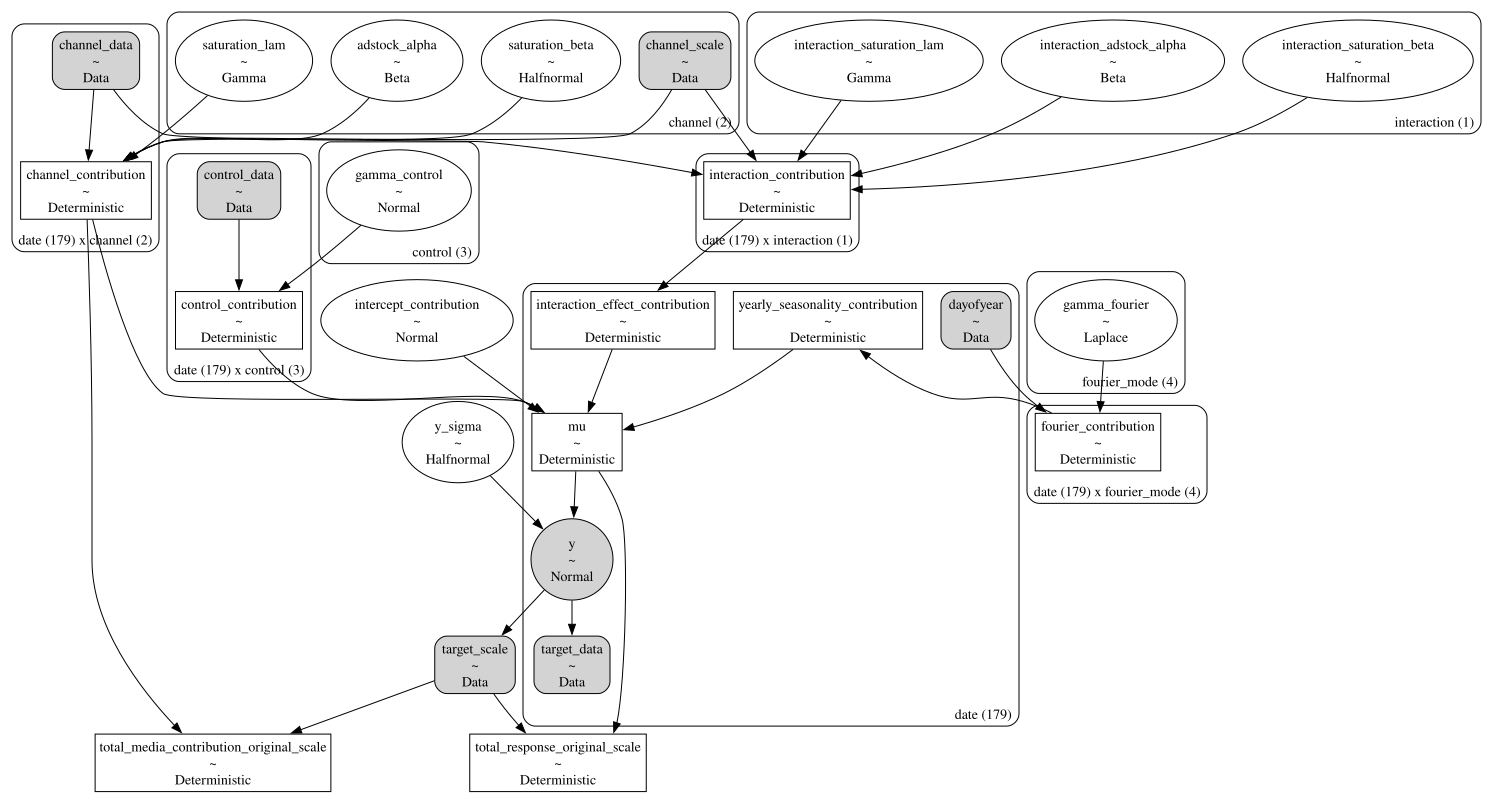

In [16]:
mmm_interaction = make_mmm().add_mu_effect(interaction)
mmm_interaction.build_model(X, y)
mmm_interaction.model.to_graphviz()

Compared with the additive model, the graph has three new parts:

1. **Interaction parameters.** The `interaction` plate holds `interaction_adstock_alpha`, `interaction_saturation_lam` and `interaction_saturation_beta`, one value per interaction.
2. **Interaction term.** `interaction_contribution` reads `channel_data` and `channel_scale`, the same spend as `channel_contribution`. Its sum over the interactions, `interaction_effect_contribution`, adds to `mu`. Both are named steps of the sales function, and the causal graph still has only the two spends as parents of sales.
3. **Total response.** `total_response_original_scale` sums `mu` on the original scale, so it includes the interaction. `total_media_contribution_original_scale` still reads `channel_contribution` only.

### Prior Predictive Checks

Before fitting, we look at what the priors allow. We measure the size of the interaction by its share of the media contribution over the training period. This share is the sum of the interaction term divided by the sum of the channel and interaction terms.

We compute the share with a helper that works on the prior and on the posterior samples.

In [17]:
def interaction_share(samples: xr.Dataset) -> xr.DataArray:
    """Return the share of the interaction in the media contribution, with dims (chain, draw)."""
    # Totals over the training period, each with dims (chain, draw)
    interaction_total = samples["interaction_effect_contribution"].sum(dim="date")
    channel_total = samples["channel_contribution"].sum(dim=("date", "channel"))
    return interaction_total / (channel_total + interaction_total)

Now we sample from the prior predictive distribution and compute the prior share.

In [18]:
_ = mmm_interaction.sample_prior_predictive(X, y, samples=2_000, random_seed=rng)

# Prior share of the interaction, dims (chain, draw)
prior_share = interaction_share(mmm_interaction.idata["prior"])

Sampling: [adstock_alpha, gamma_control, gamma_fourier, interaction_adstock_alpha, interaction_saturation_beta, interaction_saturation_lam, intercept_contribution, saturation_beta, saturation_lam, y, y_sigma]


We plot the priors of the three interaction parameters, with the priors of the channel coefficients in the panel of $\beta$, and the prior share that they imply. The title of the share panel gives its median and its $94\%$ equal-tailed interval (ETI).

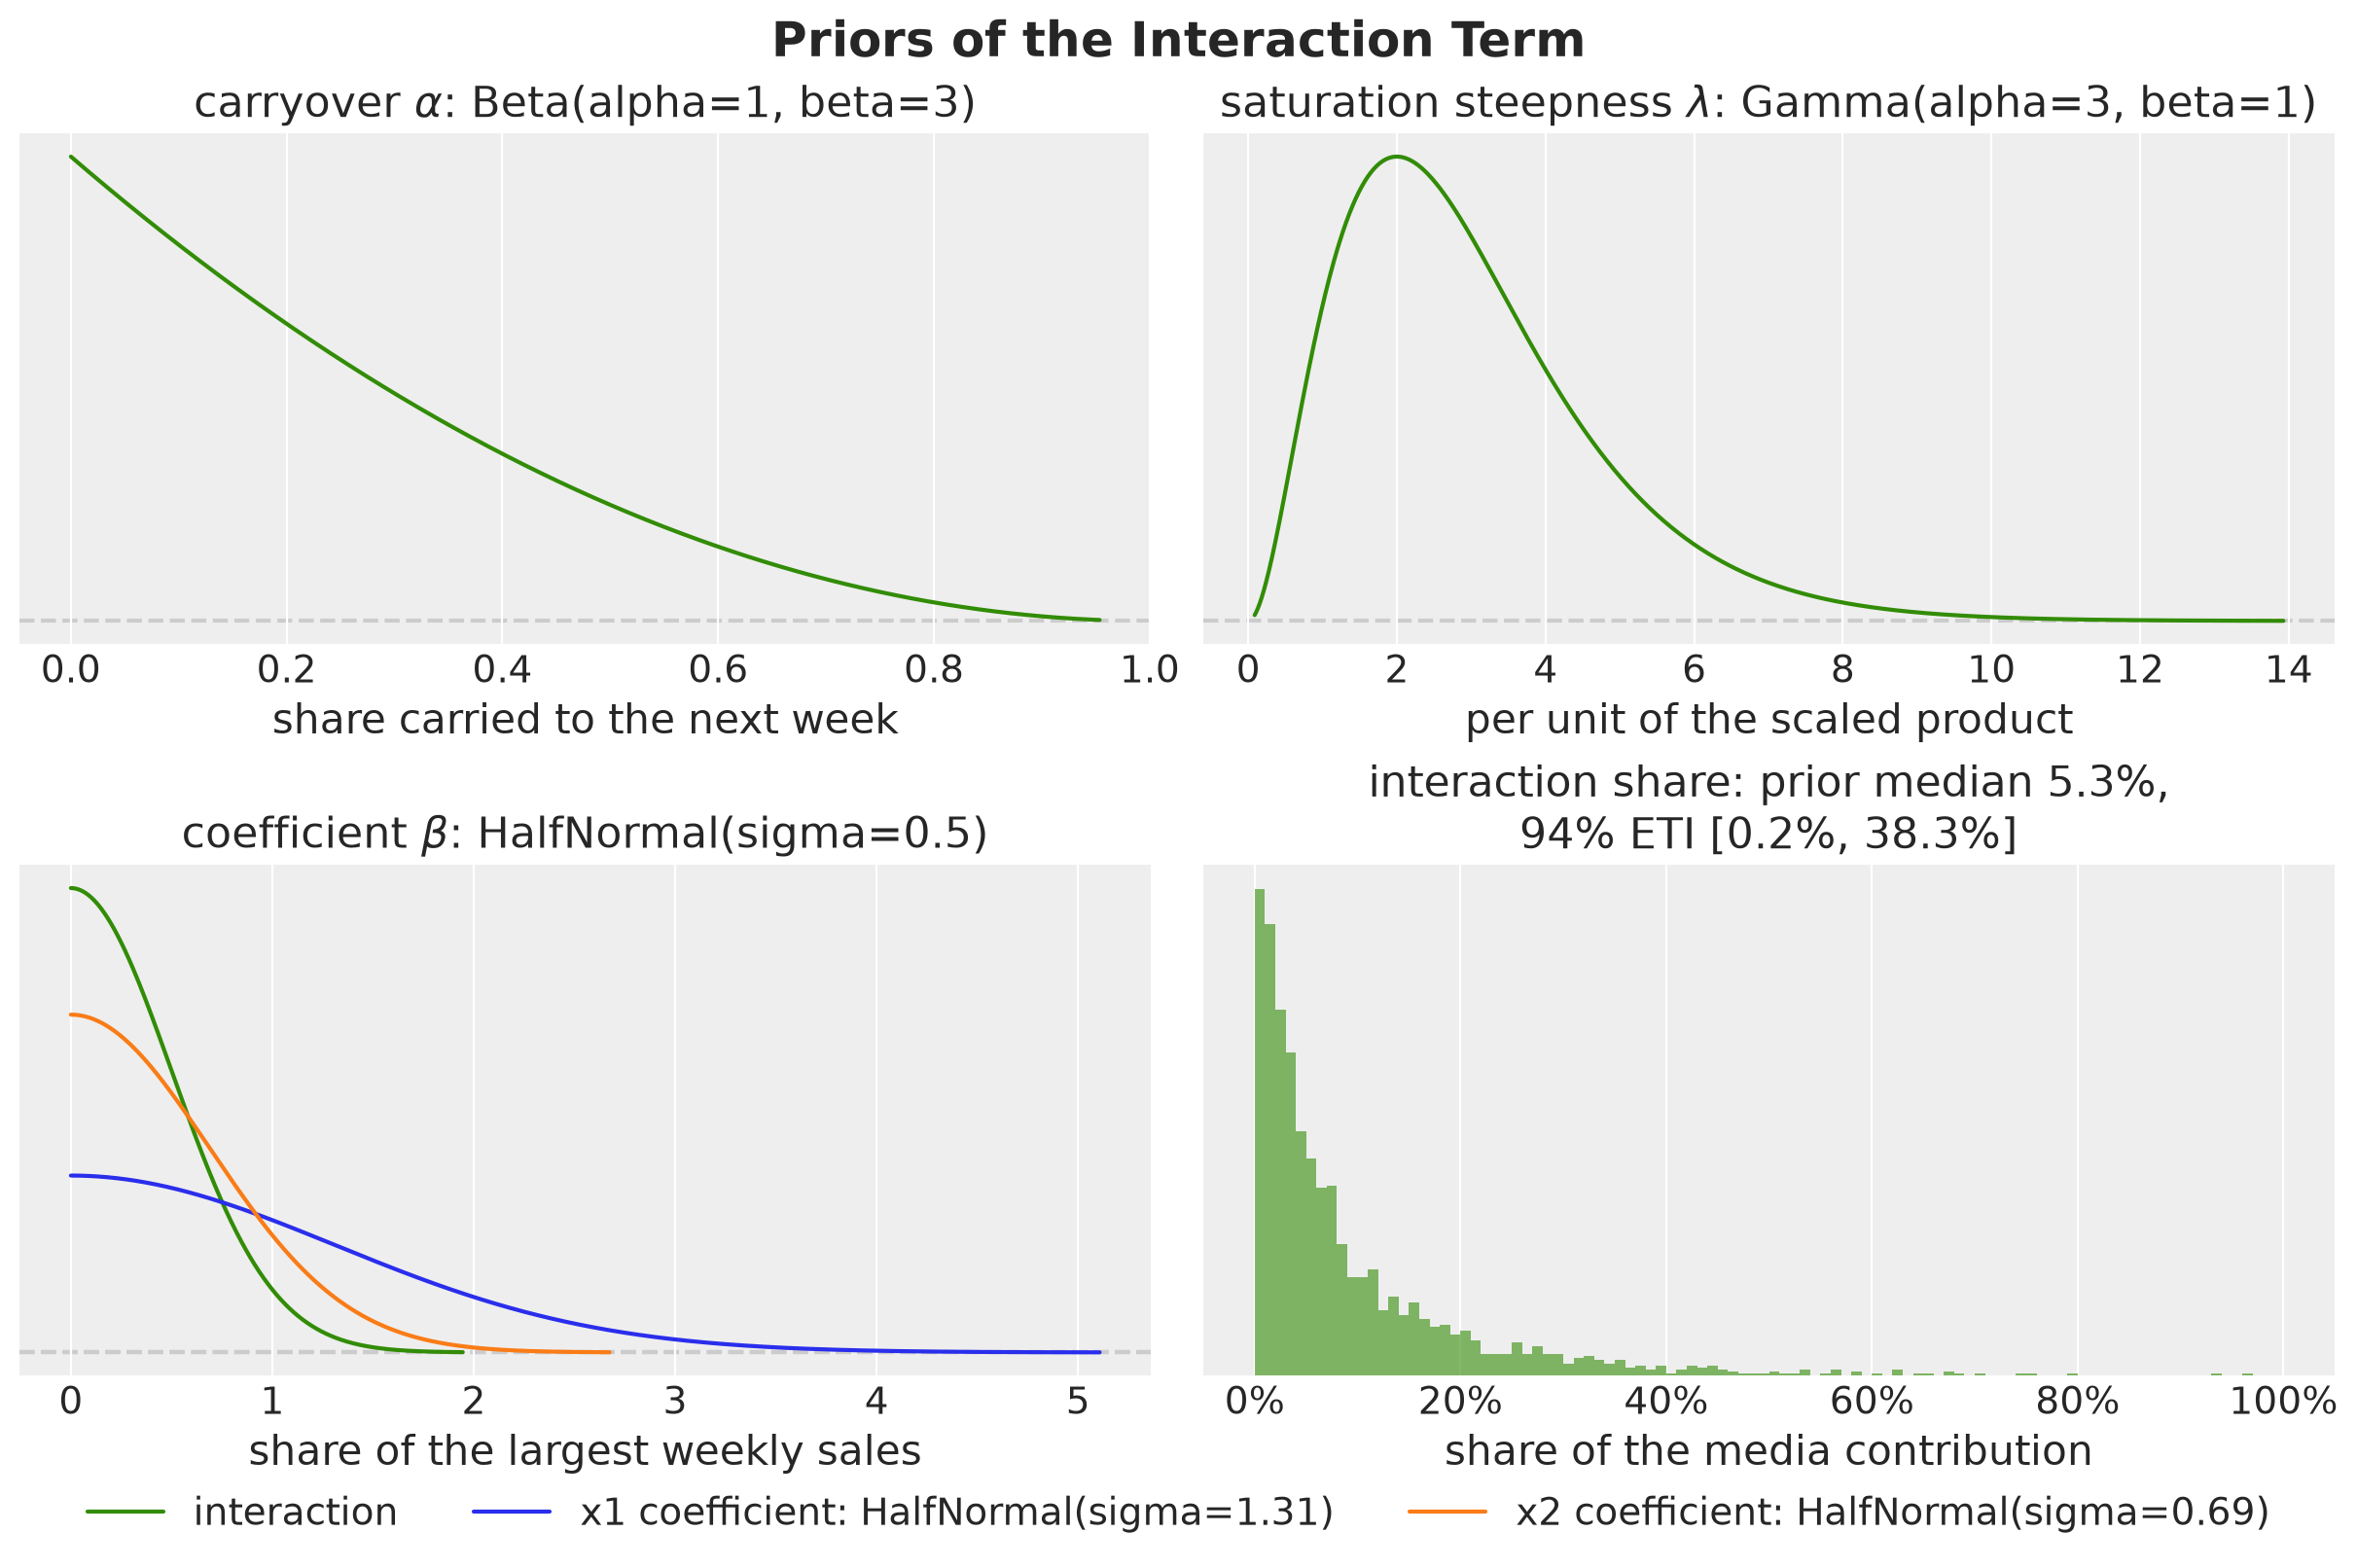

In [19]:
# Priors of the interaction parameters, keyed by the variable names in the model
interaction_priors = {
    "interaction_adstock_alpha": interaction_adstock.function_priors["alpha"],
    "interaction_saturation_lam": interaction_saturation.function_priors["lam"],
    "interaction_saturation_beta": interaction_saturation.function_priors["beta"],
}

# Title and x label of each interaction parameter in the figures
interaction_labels = {
    "interaction_adstock_alpha": (
        r"carryover $\alpha$",
        "share carried to the next week",
    ),
    "interaction_saturation_lam": (
        r"saturation steepness $\lambda$",
        "per unit of the scaled product",
    ),
    "interaction_saturation_beta": (
        r"coefficient $\beta$",
        "share of the largest weekly sales",
    ),
}

fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(12, 8), layout="constrained")

for ax, (name, prior) in zip(axes.flat, interaction_priors.items(), strict=False):
    prior.preliz.plot_pdf(ax=ax, color="C2", legend=None)
    title, xlabel = interaction_labels[name]
    ax.set(title=f"{title}: {prior.preliz}", xlabel=xlabel)

# Priors of the channel coefficients in the panel of beta, one per channel
for color, channel in zip(["C0", "C1"], CHANNELS, strict=True):
    Prior("HalfNormal", sigma=prior_sigma.sel(channel=channel).item()).preliz.plot_pdf(
        ax=axes[1, 0], color=color, legend=None
    )

# Prior share of the interaction, with its median and 94% ETI
prior_eti = prior_share.quantile([0.03, 0.97]).to_numpy()
axes[1, 1].hist(
    prior_share.to_numpy().flatten(), bins=np.linspace(0, 1, 101), color="C2", alpha=0.6
)
axes[1, 1].xaxis.set_major_formatter(mtick.PercentFormatter(xmax=1.0))
axes[1, 1].set(yticks=[], xlabel="share of the media contribution")
axes[1, 1].set_title(
    f"interaction share: prior median {prior_share.median().item():.1%},\n"
    f"$94\\%$ ETI [{prior_eti[0]:.1%}, {prior_eti[1]:.1%}]"
)

prior_handles = [
    Line2D([0], [0], color="C2", label="interaction"),
    *[
        Line2D(
            [0],
            [0],
            color=color,
            label=f"{channel} coefficient: HalfNormal(sigma={sigma:.2f})",
        )
        for color, channel, sigma in zip(
            ["C0", "C1"], CHANNELS, prior_sigma.to_numpy(), strict=True
        )
    ],
]
fig.legend(handles=prior_handles, loc="outside lower center", ncols=3)
fig.suptitle("Priors of the Interaction Term", fontsize=18, fontweight="bold");

The prior of $\alpha$ prefers a short carryover, and the prior of $\lambda$ peaks at $2$. The prior of the interaction $\beta$ is narrower than the priors of the coefficients of `x1` and `x2`. It still allows an interaction of the size of a main effect.

Before we see the data, the priors allow anything from almost no interaction to an interaction that drives more than a third of the media contribution. Half of the prior draws of the share are below $5.3\%$, the median in the title.

### Model Fitting

We fit the interaction model with the same settings as the additive model.

In [20]:
_ = mmm_interaction.fit(X, y, **fit_kwargs)

NUTS[nutpie]: [interaction_adstock_alpha, interaction_saturation_lam, interaction_saturation_beta, gamma_fourier, gamma_control, adstock_alpha, saturation_lam, saturation_beta, intercept_contribution, y_sigma]


Output()

We run the same diagnostics as for the additive model.

In [21]:
_ = az.diagnose(
    mmm_interaction.idata,
    var_names=[variable.name for variable in mmm_interaction.model.free_RVs],
)

Divergences
No divergent transitions found.

E-BFMI
E-BFMI satisfactory for all chains.

ESS
Effective sample size satisfactory for all parameters.

R-hat
R-hat values satisfactory for all parameters.

Processing complete, no problems detected.


The interaction model passes every check too.

### Interaction Contribution

Now that the diagnostics look good, we can look into the interaction contribution. We multiply `interaction_contribution` by the target scale to get it in units of sales.

In [22]:
posterior = mmm_interaction.idata["posterior"]
target_scale = float(mmm_interaction.idata["constant_data"]["target_scale"])

# Weekly interaction contribution on the original scale, dims (chain, draw, date)
interaction_sales = (
    posterior["interaction_contribution"].sel(interaction="x1:x2") * target_scale
)

# Lower and upper bound of the 94% HDI, dims (date, ci_bound)
interaction_sales_hdi = az.hdi(interaction_sales, prob=0.94)

We plot the posterior mean and the $94\%$ HDI, and we shade the weeks with spend on `x2`. The dashed line marks the true interaction, which is zero.

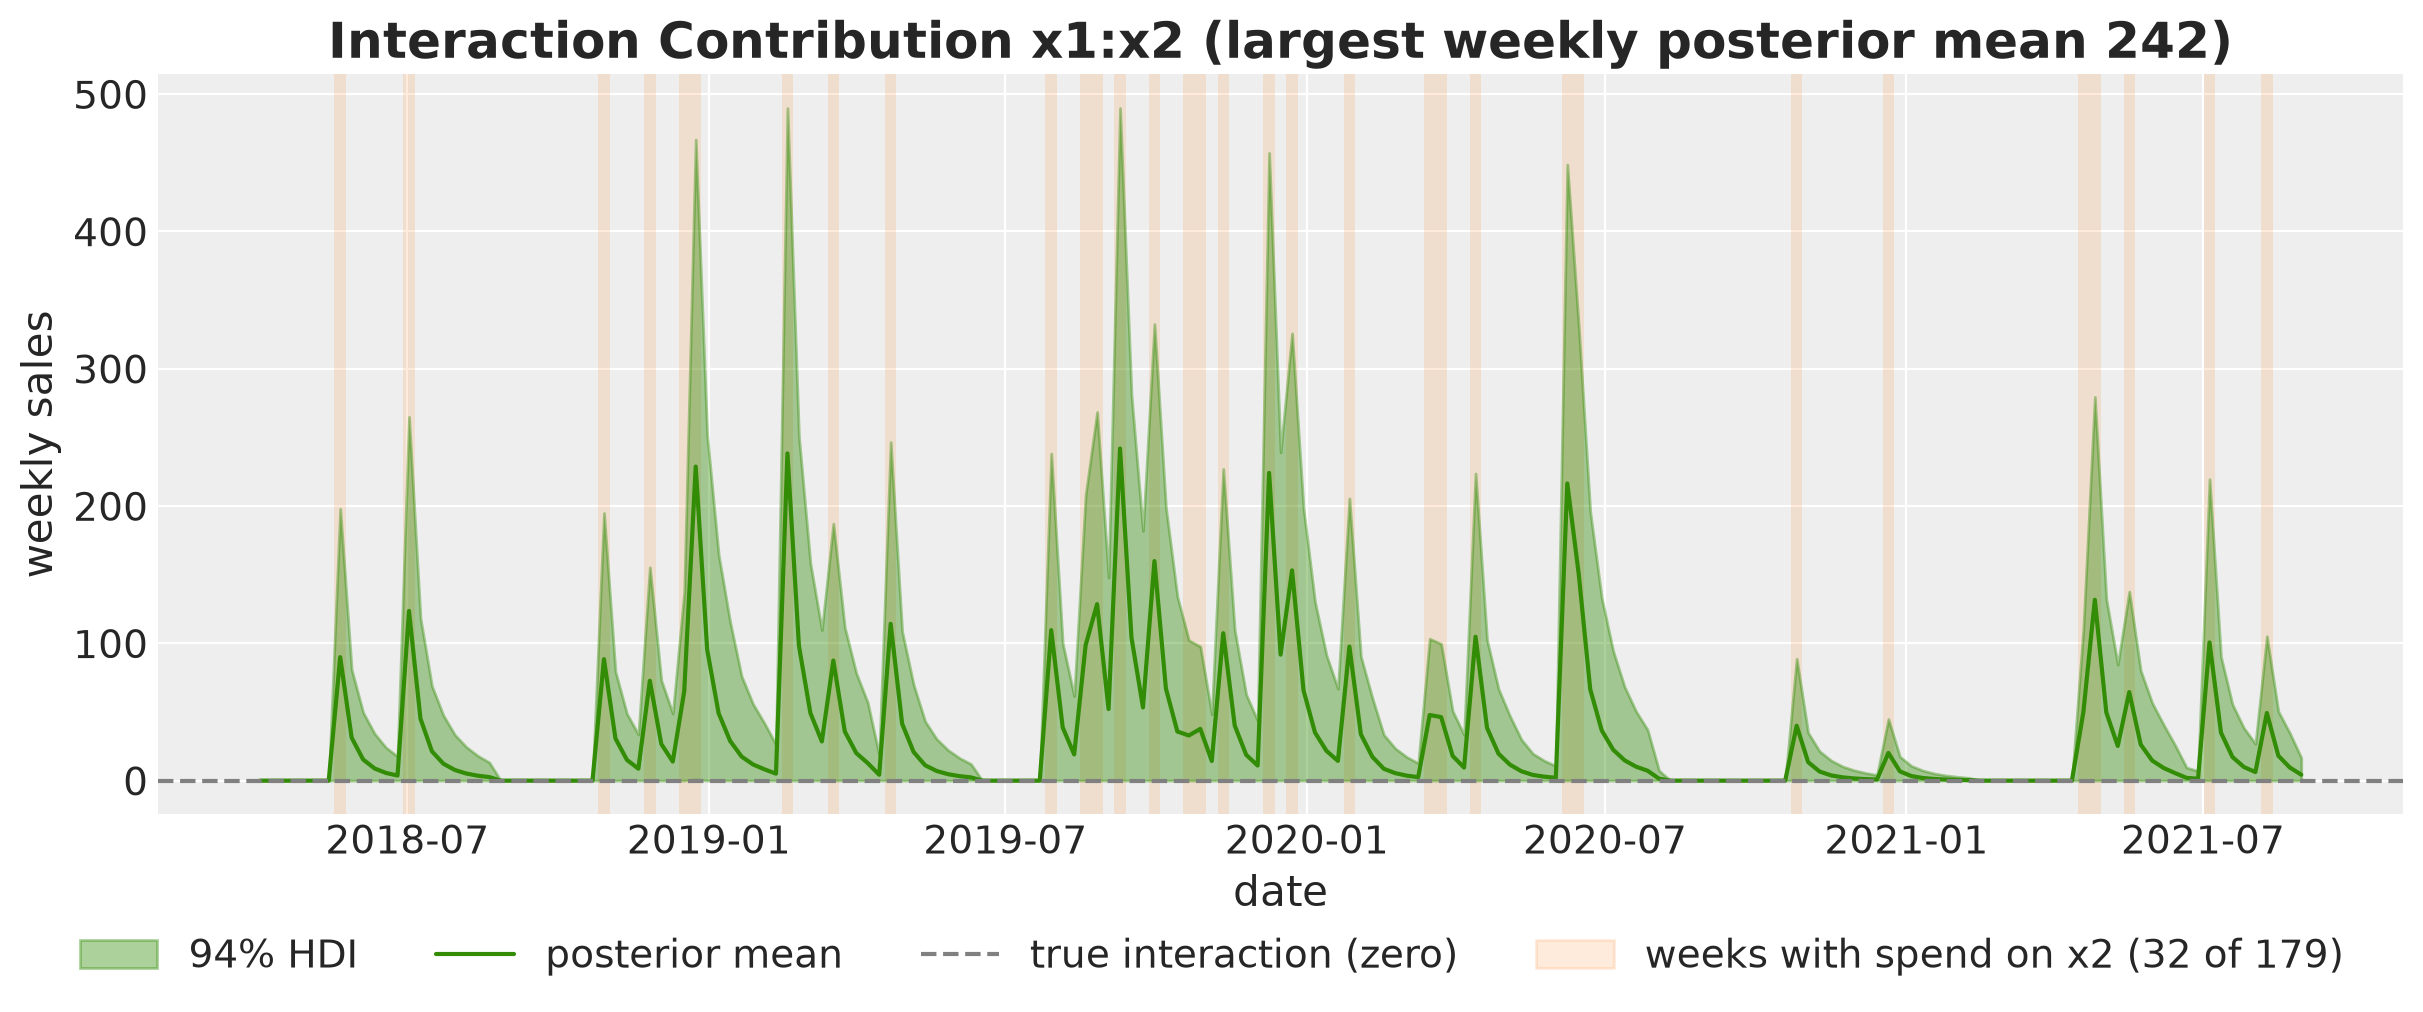

In [23]:
fig, ax = plt.subplots(figsize=(12, 5), layout="constrained")
x2_handle = shade_x2_weeks(ax)
ax.fill_between(
    data["date_week"],
    interaction_sales_hdi.sel(ci_bound="lower"),
    interaction_sales_hdi.sel(ci_bound="upper"),
    color="C2",
    alpha=0.4,
    label=r"$94\%$ HDI",
)
ax.plot(
    data["date_week"],
    interaction_sales.mean(dim=("chain", "draw")),
    color="C2",
    label="posterior mean",
)
ax.axhline(0, color="gray", linestyle="--", label="true interaction (zero)")
fig.legend(
    handles=[*ax.get_legend_handles_labels()[0], x2_handle],
    loc="outside lower center",
    ncols=4,
)
ax.set(xlabel="date", ylabel="weekly sales")
ax.set_title(
    "Interaction Contribution x1:x2 "
    f"(largest weekly posterior mean {interaction_sales.mean(dim=('chain', 'draw')).max().item():.0f})",
    fontsize=18,
    fontweight="bold",
);

The estimated interaction adds sales in the weeks with spend on `x2`, and in the weeks after them through its adstock. Its posterior mean peaks at $242$ sales in a week, while the true interaction is zero.

This positive estimate is not evidence of a synergy. The half-normal prior gives $\beta > 0$ in every draw, so the term is positive in every week with adstocked input. Its posterior mean stays above zero even when the data favor no interaction, and the lower edge of the HDI band stays close to zero in every week.

## Return on Ad Spend (ROAS)

To have a more quantitative metric of efficiency, we turn to ROAS. As we know the process that generated the data, we know the true ROAS.

Recall from {ref}`mmm_multiplicative` that each channel adds $1000 \cdot \beta_c \cdot L_{\lambda_c}(A_{\alpha_c}(x_c))$ to the weekly sales, with $\alpha = (0.4, 0.2)$, $\lambda = (4, 3)$ and $\beta = (3, 2)$. The helper below applies these true transformations to the spend of one channel.

In [24]:
TRUE_PARAMS = {
    "x1": {"alpha": 0.4, "lam": 4.0, "beta": 3.0},
    "x2": {"alpha": 0.2, "lam": 3.0, "beta": 2.0},
}
AMPLITUDE = 1_000  # scale between the true process and the data
L_MAX = 8  # adstock length of the true process


def true_channel_sales(
    spend: np.ndarray, alpha: float, lam: float, beta: float
) -> np.ndarray:
    """Return the true weekly sales of one channel (normalized adstock, logistic saturation)."""
    # Adstock weights alpha^l / sum(alpha^l) for the lags l = 0, ..., L_MAX - 1, shape (L_MAX,)
    weights = alpha ** np.arange(L_MAX)
    weights /= weights.sum()

    # Causal convolution, keeping the first len(spend) weeks, shape (week,)
    adstocked = np.convolve(spend, weights)[: len(spend)]
    saturated = (1 - np.exp(-lam * adstocked)) / (1 + np.exp(-lam * adstocked))
    return AMPLITUDE * beta * saturated

The true ROAS of a channel is its true sales over the training period divided by its spend. We also compute the ROAS of both channels together, which we call `all channels`: the true sales of both channels divided by their total spend.

In [25]:
# True sales and spend of each channel over the training period, shape (channel,)
true_channel_totals = pd.Series(
    {
        channel: true_channel_sales(
            data[channel].to_numpy(), **TRUE_PARAMS[channel]
        ).sum()
        for channel in CHANNELS
    }
)
total_spend = data[CHANNELS].sum()

# True ROAS of each channel and of both channels together, shape (channel + 1,)
true_roas = true_channel_totals / total_spend
true_roas["all channels"] = true_channel_totals.sum() / total_spend.sum()

The `mmm.incrementality` module sets the spend of a channel to zero and divides the drop in predicted sales by the spend of the channel. For the interaction model, a zero spend on `x1` or on `x2` also removes the interaction term. For `all channels`, we set the spend of both channels to zero together with {meth}`~pymc_marketing.mmm.incrementality.Incrementality.compute_joint_incremental_contribution`.

In [26]:
models = {"Additive": mmm_additive, "Interaction": mmm_interaction}
roas = {}

for name, mmm in models.items():
    # ROAS of each channel, dims (chain, draw, channel)
    per_channel_roas = mmm.incrementality.contribution_over_spend(frequency="all_time")

    # ROAS of both channels together, dims (chain, draw)
    joint_sales = mmm.incrementality.compute_joint_incremental_contribution(
        frequency="all_time"
    )
    joint_roas = (joint_sales / data[CHANNELS].sum().sum()).squeeze(drop=True)

    # dims (chain, draw, channel), with "all channels" as a third entry of the channel dim
    roas[name] = xr.concat(
        [per_channel_roas, joint_roas.expand_dims(channel=["all channels"])],
        dim="channel",
    )

To compare the channels on one axis, we divide the ROAS by the true ROAS, so that $1$ means a perfect estimate. The channel labels carry the true ROAS.

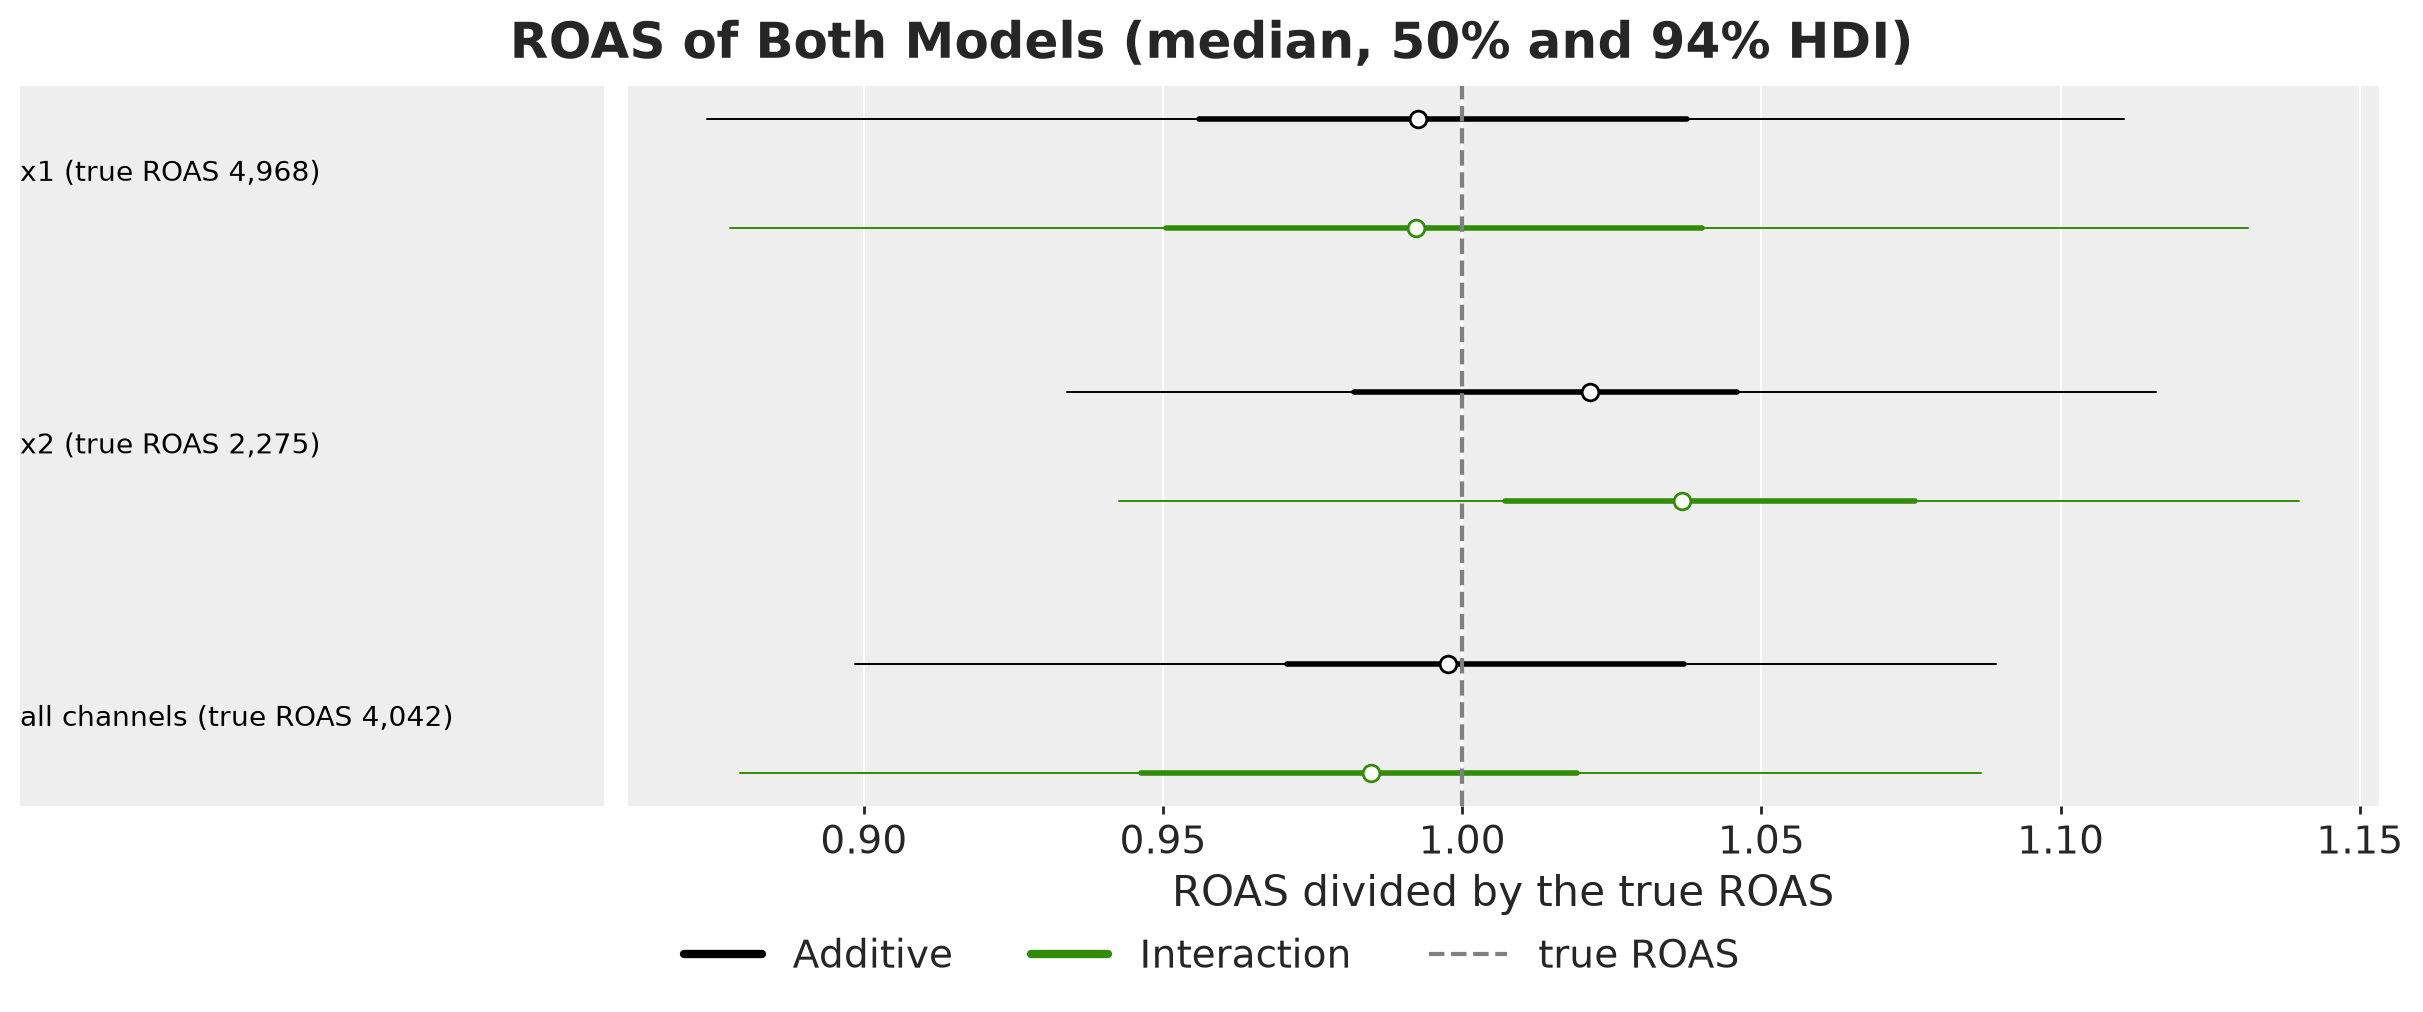

In [27]:
# True ROAS with the labels of the forest plot, dims (channel,)
roas_labels = [
    f"{channel} (true ROAS {value:,.0f})" for channel, value in true_roas.items()
]
true_roas_da = xr.DataArray(
    true_roas.to_numpy(), dims="channel", coords={"channel": true_roas.index}
)

# ROAS divided by the true ROAS, one DataTree per model, each with dims (chain, draw, channel)
roas_ratio = {
    name: xr.DataTree.from_dict(
        {
            "posterior": xr.Dataset(
                {
                    "roas_ratio": (samples / true_roas_da).assign_coords(
                        channel=roas_labels
                    )
                }
            )
        }
    )
    for name, samples in roas.items()
}
model_colors = {"Additive": "black", "Interaction": "C2"}

pc = azp.plot_forest(
    roas_ratio,
    combined=True,
    point_estimate="median",
    ci_kind="hdi",
    ci_probs=(0.5, 0.94),
    labels=["channel"],
    color=list(model_colors.values()),
    figure_kwargs={"figsize": (12, 5), "width_ratios": [1, 3], "layout": "constrained"},
)
pc.viz["plot"].sel(column="labels").item().set_xticks([])
ax = pc.viz["plot"].sel(column="forest").item()
ax.axvline(1, color="gray", linestyle="--")
ax.set(xlabel="ROAS divided by the true ROAS")

roas_handles = [
    *[
        Line2D([0], [0], color=color, linewidth=3, label=name)
        for name, color in model_colors.items()
    ],
    Line2D([0], [0], color="gray", linestyle="--", label="true ROAS"),
]
fig = pc.viz["figure"].item()
fig.legend(handles=roas_handles, loc="outside lower center", ncols=3)
fig.suptitle(
    "ROAS of Both Models (median, 50% and 94% HDI)", fontsize=18, fontweight="bold"
);

Both models recover the true ROAS. For `x1`, `x2` and all channels together, the $94\%$ HDI of both models contains $1$, and the posterior medians stay within a few percent of the truth. The interaction hardly changes the ROAS on this data.

```{note}
**Totals over channels**: A zero spend on `x1` removes the interaction term, and so does a zero spend on `x2`. The incremental sales of `x1` and of `x2` therefore both include the interaction, and their sum counts it twice. For a total over channels that interact, use the joint incremental sales, as we do for `all channels`.
```

## Budget Optimization

Next, we plan the budget of the next quarter with both models. We use the planning setup of {ref}`mmm_multiplicative` to compare the plans with the plans of that notebook:

1. **Window.** The $13$ weeks after the last observation, from 2021-09-06 to 2021-11-29.
2. **Budget.** The weekly budget is the average weekly spend over the training data. The reference plan is the **historical split**: the average weekly spend of each channel.
3. **Guardrails.** Each channel can move at most $50\%$ away from its historical weekly spend.
4. **Solver.** SLSQP, starting at the historical split, with a tolerance relative to the objective at the starting plan.

In [28]:
# The 13 weeks after the last observation
start_date, end_date = "2021-09-06", "2021-11-29"
n_plan_weeks = 13

# Historical split: average weekly spend of each channel, shape (channel,)
historical_spend = data[CHANNELS].mean()
weekly_budget = float(historical_spend.sum())

# Each channel can move at most 50% away from its historical spend, shape (channel, bound)
percentage_change = 0.5
guardrails = xr.DataArray(
    np.stack(
        [
            (1 - percentage_change) * historical_spend,
            (1 + percentage_change) * historical_spend,
        ],
        axis=1,
    ),
    dims=["channel", "bound"],
    coords={"channel": CHANNELS, "bound": ["lower", "upper"]},
)

# Without guardrails: each channel between zero and the full weekly budget, shape (channel, bound)
no_guardrails = xr.DataArray(
    [[0.0, weekly_budget]] * len(CHANNELS),
    dims=["channel", "bound"],
    coords={"channel": CHANNELS, "bound": ["lower", "upper"]},
)

Now we create the optimizers. For the interaction model we pass `response_variable="total_response_original_scale"`, so that the objective includes the interaction. The default objective, `total_media_contribution_original_scale`, sums the channel terms only, and `MMM.budget_optimizer` warns about this when a mu effect reads the channel spend.

To see what the objective changes, we also create a second optimizer for the interaction model with the default objective, which we pass explicitly to silence the warning.

```{note}
**Baseline in the objective**: `total_response_original_scale` also includes the baseline, which does not depend on the plan. The optimal plan stays the same for the default utility, the posterior mean of the objective. A risk-averse utility would also see the uncertainty of the baseline (see {ref}`mmm_allocation_assessment`).
```

In [29]:
optimizers = {
    "Additive": mmm_additive.budget_optimizer(start_date=start_date, end_date=end_date),
    "Interaction, media-only objective": mmm_interaction.budget_optimizer(
        start_date=start_date,
        end_date=end_date,
        response_variable="total_media_contribution_original_scale",
    ),
    "Interaction": mmm_interaction.budget_optimizer(
        start_date=start_date,
        end_date=end_date,
        response_variable="total_response_original_scale",
    ),
}

We wrap the optimization in a helper, with the solver settings above.

In [30]:
def optimize_budget(optimizer: BudgetOptimizer, bounds: xr.DataArray) -> pd.Series:
    """Return the optimal weekly spend per channel within the bounds."""
    # Historical split as the starting plan, shape (channel,)
    x0 = xr.DataArray(
        historical_spend.to_numpy(), dims="channel", coords={"channel": CHANNELS}
    )

    # SLSQP's ftol is an absolute tolerance, so we scale it with the objective at the starting plan
    objective_scale = max(
        abs(optimizer.evaluate_plan({"channel_data": x0}).objective), 1.0
    )

    result = optimizer.allocate_budget(
        total_budget=weekly_budget,
        budget_bounds=bounds,
        x0=x0,
        minimize_kwargs={
            "method": "SLSQP",
            "options": {"ftol": 1e-9 * objective_scale, "maxiter": 1_000},
        },
    )
    return result.budgets.to_series()

Because we know the true process, we can also find the true optimal plan and score every plan with its true incremental sales. To get the true incremental sales of a flat plan, we append the plan weeks and `L_MAX` weeks without spend to the observed spend. Then we subtract the sales of the same history without any spend in the window.

In [31]:
def true_incremental_sales(weekly_spend: pd.Series) -> float:
    """Return the true incremental sales of a flat plan over its plan and carryover weeks."""
    total = 0.0

    for channel, params in TRUE_PARAMS.items():
        history = data[channel].to_numpy()

        # Spend history, then the plan weeks, then L_MAX carryover weeks without spend, shape (week,)
        with_plan = np.concatenate(
            [history, np.full(n_plan_weeks, weekly_spend[channel]), np.zeros(L_MAX)]
        )
        without_plan = np.concatenate([history, np.zeros(n_plan_weeks + L_MAX)])

        # Lift of the plan in the plan and carryover weeks
        lift = true_channel_sales(with_plan, **params) - true_channel_sales(
            without_plan, **params
        )
        total += lift[len(history) :].sum()

    return total

With two channels, the budget line $x_1 + x_2 = B$, where $B$ is the weekly budget, leaves one free variable: the spend on `x1`. The true sales are concave in it, so a bounded scalar search finds the true optimum. The next helper calls `optimize_budget` for each optimizer, and it compares the plans with the historical split and the true optimum, within given bounds.

In [32]:
def compare_plans(bounds: xr.DataArray) -> pd.DataFrame:
    """Return the plans of the optimizers, the historical split and the true optimum, with their true sales."""
    lower = bounds.sel(bound="lower").to_series()
    upper = bounds.sel(bound="upper").to_series()

    # Range of the x1 spend on the budget line that respects the bounds of both channels
    x1_range = (
        max(lower["x1"], weekly_budget - upper["x2"]),
        min(upper["x1"], weekly_budget - lower["x2"]),
    )
    true_x1 = minimize_scalar(
        lambda x1: (
            -true_incremental_sales(pd.Series({"x1": x1, "x2": weekly_budget - x1}))
        ),
        bounds=x1_range,
        method="bounded",
    ).x

    # One row per plan, one column per channel
    plans = pd.DataFrame(
        {
            "Historical split": historical_spend,
            **{
                name: optimize_budget(optimizer, bounds)
                for name, optimizer in optimizers.items()
            },
            "True optimum": pd.Series({"x1": true_x1, "x2": weekly_budget - true_x1}),
        }
    ).T

    # True incremental sales of each plan, relative to the true optimum
    plan_sales = plans.apply(true_incremental_sales, axis=1)
    plans["gap to true optimum"] = plan_sales / plan_sales["True optimum"] - 1
    return plans

Now we are ready to pass all these business requirements to the optimizer. We optimize with and without the guardrails.

In [33]:
plans = {
    "with guardrails (historical spend ± 50%)": compare_plans(guardrails),
    "without guardrails (0 to the full budget)": compare_plans(no_guardrails),
}

Let's visualize the plans. Each plan spends the same amount in each of the $13$ weeks.

After each bar we show the weekly spend on `x2` and, in parentheses, the gap to the true optimum of the same panel. The gap is the relative difference in true incremental sales, and a negative value means fewer sales.

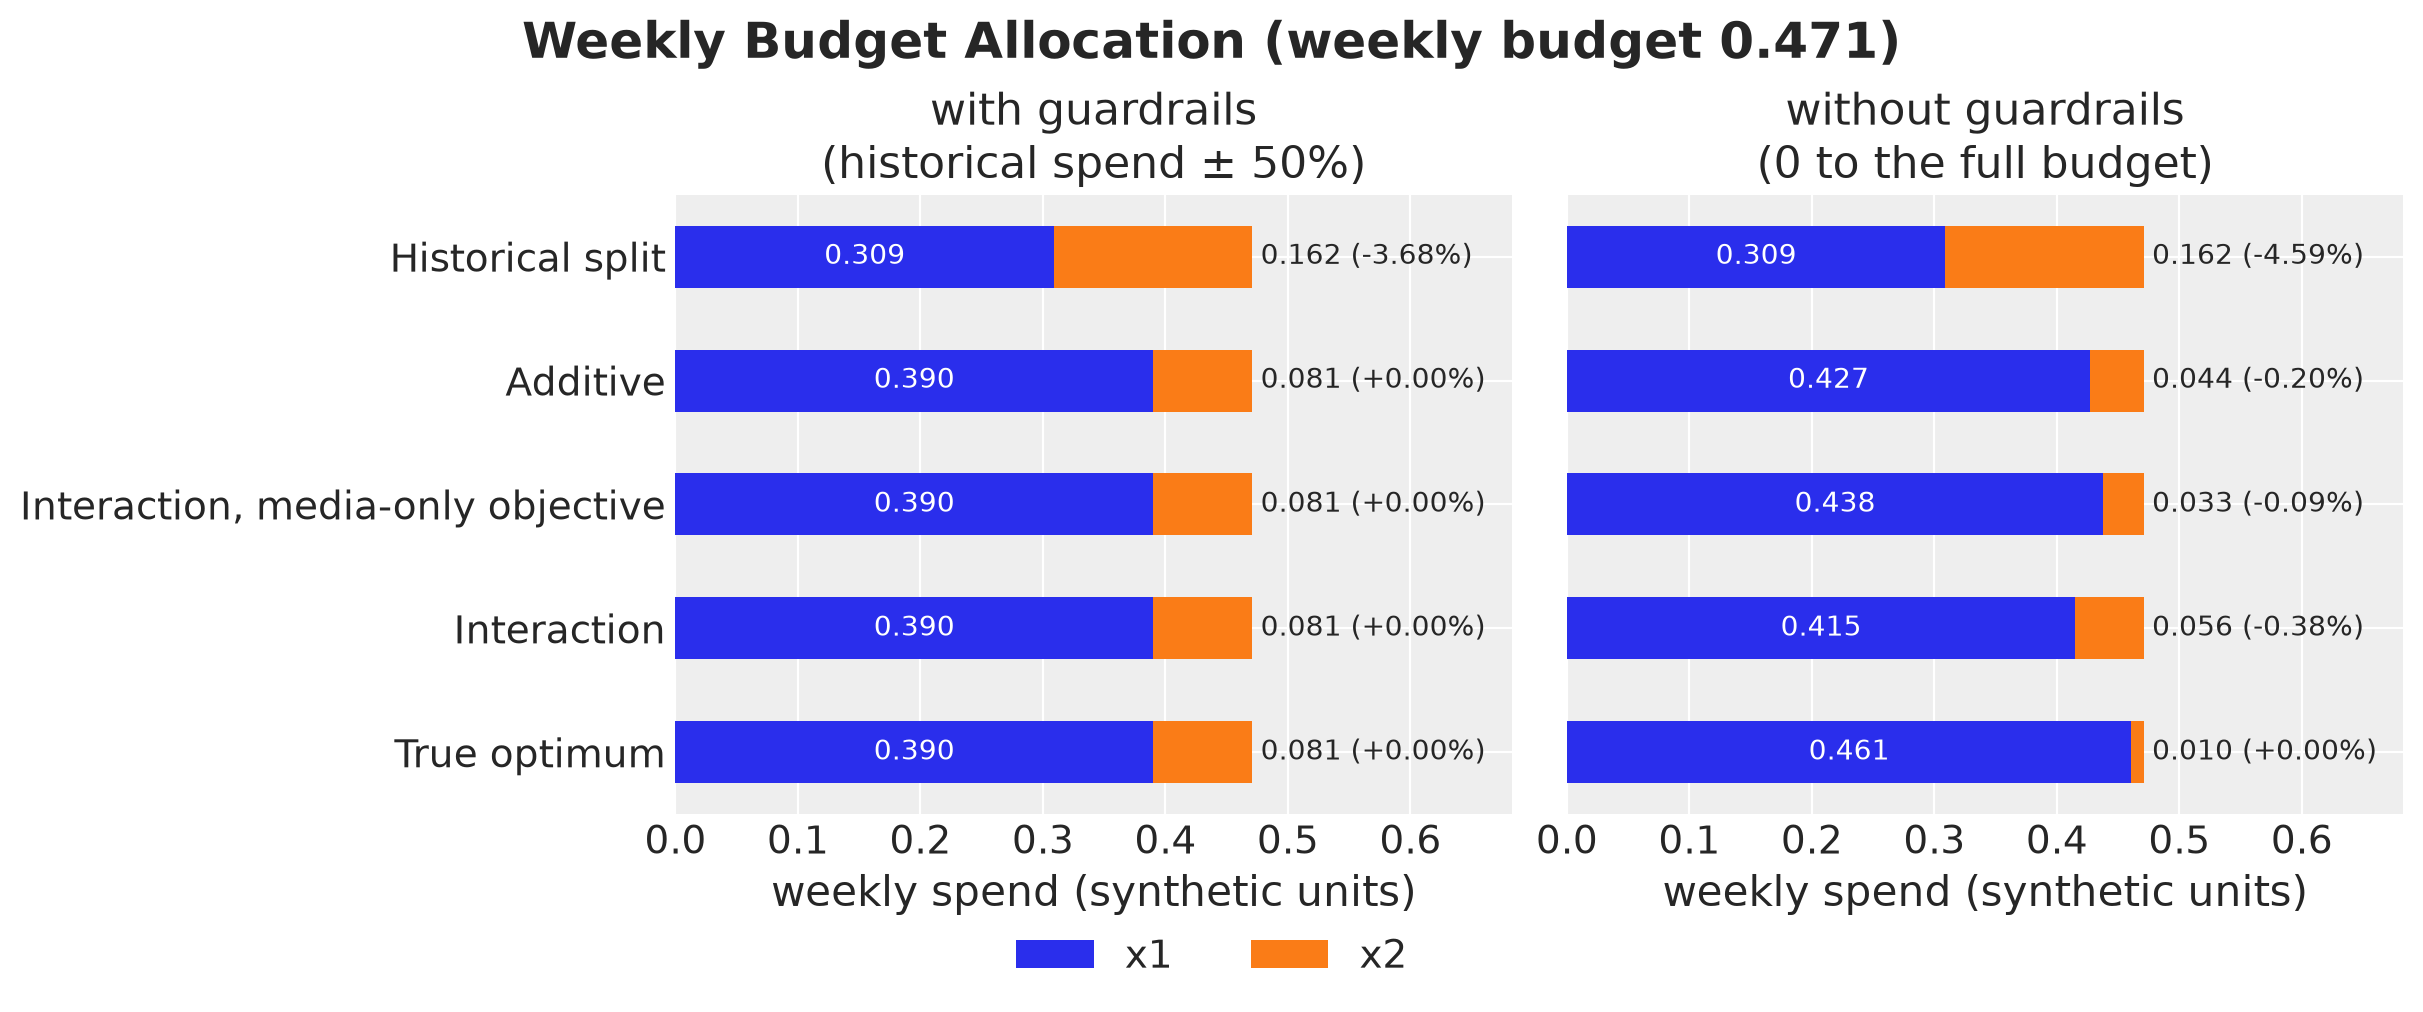

In [34]:
fig, axes = plt.subplots(
    nrows=1, ncols=2, figsize=(12, 5), sharey=True, layout="constrained"
)

for ax, (scenario, scenario_plans) in zip(axes, plans.items(), strict=True):
    scenario_plans[CHANNELS].iloc[::-1].plot.barh(
        stacked=True, color=["C0", "C1"], ax=ax, legend=False
    )

    # x1 spend inside the bars; x2 spend and the gap to the true optimum after the end of the bars
    ax.bar_label(ax.containers[0], fmt="%.3f", label_type="center", color="white")
    ax.bar_label(
        ax.containers[1],
        labels=[
            f"{x2:.3f} ({gap:+.2%})"
            for x2, gap in scenario_plans[["x2", "gap to true optimum"]]
            .iloc[::-1]
            .values
        ],
        label_type="edge",
        padding=3,
    )
    ax.set(
        xlabel="weekly spend (synthetic units)",
        ylabel="",
        xlim=(0, 1.45 * weekly_budget),
    )
    ax.set_title(scenario.replace(" (", "\n("))

fig.legend(
    handles=axes[0].containers, labels=CHANNELS, loc="outside lower center", ncols=2
)
fig.suptitle(
    f"Weekly Budget Allocation (weekly budget {weekly_budget:.3f})",
    fontsize=18,
    fontweight="bold",
);

Within the guardrails, the three optimized plans and the true optimum are the same: `x2` gets its lower guardrail, $0.081$, and `x1` gets the rest, $0.390$. The guardrails decide the plan, and the interaction does not change it. The models of {ref}`mmm_multiplicative` choose the same plan (we do not re-run them here).

Without guardrails, all models move most of the budget to `x1`, as the true optimum does, but they keep more on `x2`. The interaction model keeps the most, $0.056$, against $0.044$ for the additive model and $0.010$ for the true optimum.

The two interaction plans come from the same posterior and differ only in the objective. The full response counts the interaction term, which grows with the spend on both channels, and gives `x2` $0.056$ instead of $0.033$. The interaction plan is $0.38\%$ below the true optimum in true incremental sales, against $0.20\%$ for the additive plan. The cost of the synergy that the model estimates is therefore small.

The media-only plan of the interaction model comes closest to the true optimum, with a gap of $0.09\%$, because it gives `x2` the least budget of all models.

## Value of the Interaction

First, we compare the priors and the posteriors of the interaction parameters and of the interaction share. The dashed lines mark the true $\beta$ and the true share, which are zero. The carryover and the steepness have no true value, because the true process has no interaction term.

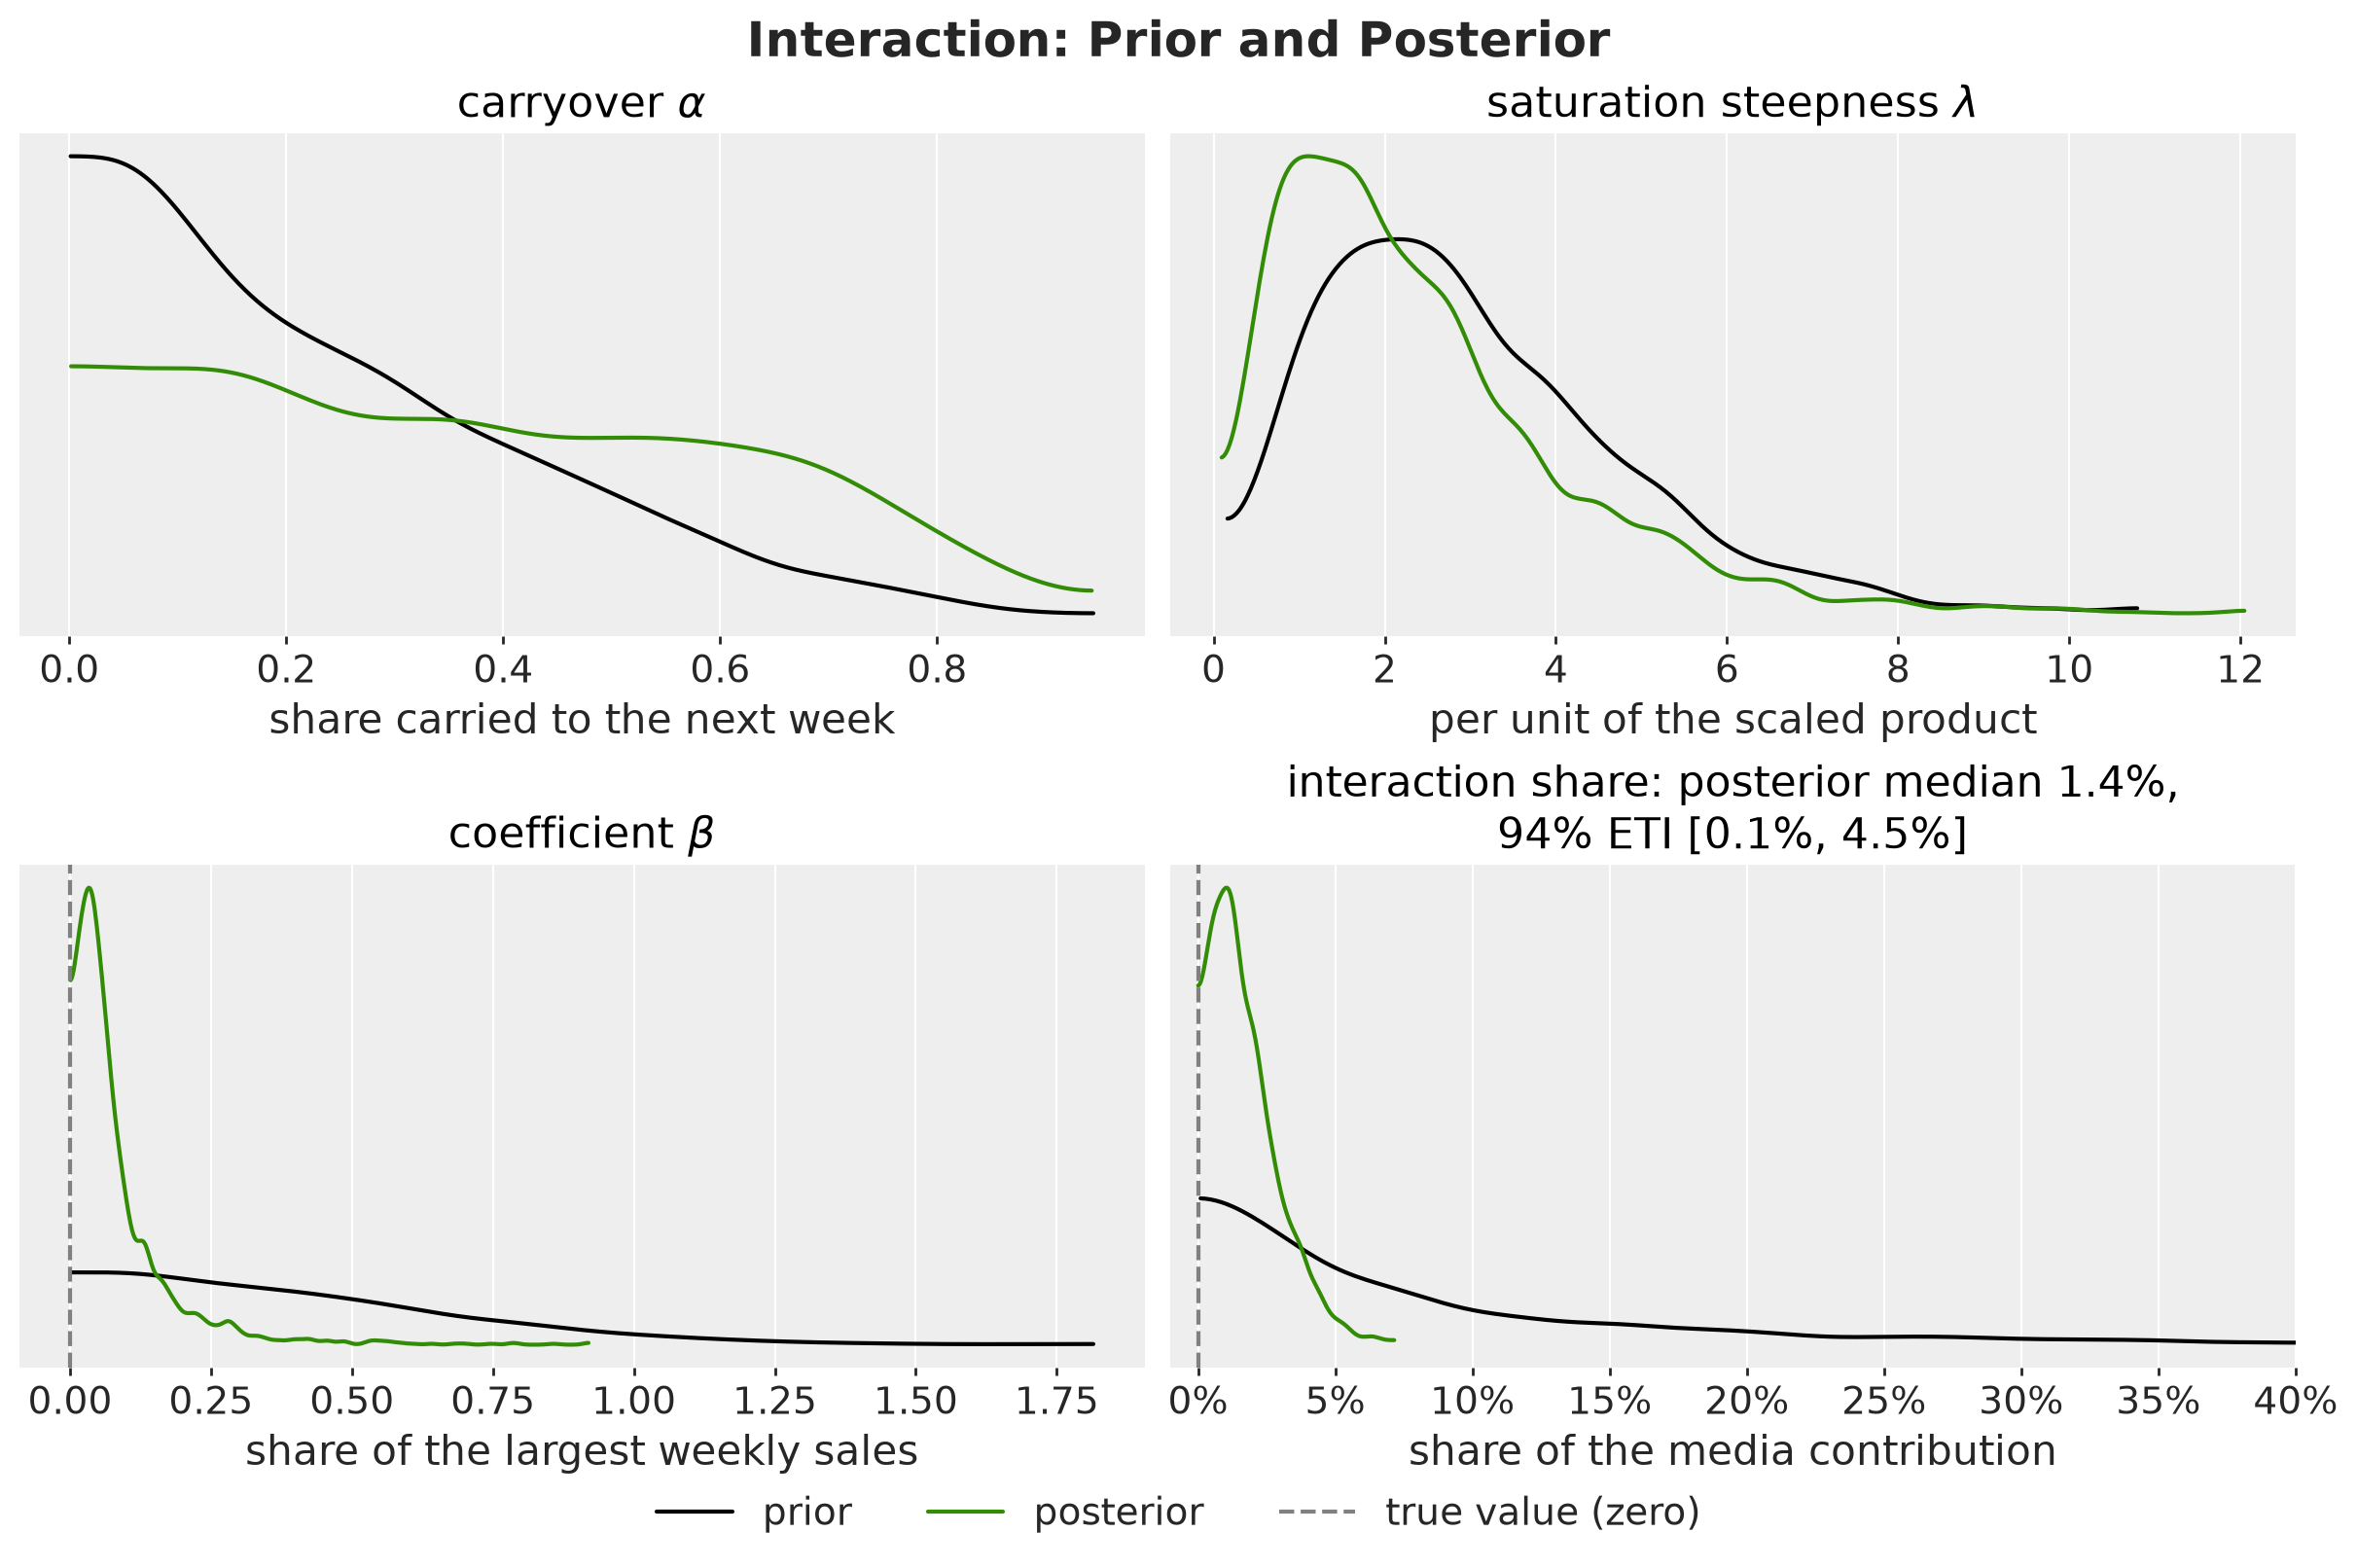

In [35]:
# Prior and posterior samples of the interaction parameters and share, each with dims (chain, draw)
prior_posterior = xr.DataTree.from_dict(
    {
        group: xr.Dataset(
            {
                **{
                    name: samples[name].sel(interaction="x1:x2", drop=True)
                    for name in interaction_priors
                },
                "interaction_share": interaction_share(samples),
            }
        )
        for group, samples in {
            "prior": mmm_interaction.idata["prior"],
            "posterior": posterior,
        }.items()
    }
)

pc = azp.plot_prior_posterior(
    prior_posterior,
    col_wrap=2,
    color=["black", "C2"],
    figure_kwargs={"figsize": (12, 8), "layout": "constrained"},
)

# Readable titles and x labels of the parameter panels
for name, (title, xlabel) in interaction_labels.items():
    pc.viz["plot"][name].item().set(title=title, xlabel=xlabel)

# The true beta and the true share are zero; alpha and lambda have no true value without an interaction
for name in ["interaction_saturation_beta", "interaction_share"]:
    pc.viz["plot"][name].item().axvline(0, color="gray", linestyle="--")

# Posterior share with its median and 94% ETI in the title; the prior share has a long tail, so we zoom in
posterior_share = prior_posterior["posterior"]["interaction_share"]
posterior_eti = posterior_share.quantile([0.03, 0.97]).to_numpy()
share_ax = pc.viz["plot"]["interaction_share"].item()
share_ax.set_xlim(-0.01, 0.4)
share_ax.xaxis.set_major_formatter(mtick.PercentFormatter(xmax=1.0, decimals=0))
share_ax.set(xlabel="share of the media contribution")
share_ax.set_title(
    f"interaction share: posterior median {posterior_share.median().item():.1%},\n"
    f"$94\\%$ ETI [{posterior_eti[0]:.1%}, {posterior_eti[1]:.1%}]"
)

# Legend at the bottom, with the true-value line
pc.viz["legend"]["group"].item().remove()
fig = pc.viz["figure"].item()
fig.legend(
    handles=[
        Line2D([0], [0], color="black", label="prior"),
        Line2D([0], [0], color="C2", label="posterior"),
        Line2D([0], [0], color="gray", linestyle="--", label="true value (zero)"),
    ],
    loc="outside lower center",
    ncols=3,
)
fig.suptitle("Interaction: Prior and Posterior", fontsize=18, fontweight="bold");

The data pulls $\beta$ and the share of the interaction toward zero. The posterior median of the share is $1.4\%$, with a $94\%$ ETI from $0.1\%$ to $4.5\%$, while the prior allows much larger shares. As we saw for the interaction contribution, the half-normal prior keeps the share above zero, so the positive share is not evidence of a synergy.

The posteriors of $\alpha$ and $\lambda$ stay wide, so the data does not pin down the carryover and the saturation of the interaction.

Next, we compare the out-of-sample predictive performance of both models with leave-one-out cross-validation (LOO). We compute the pointwise log-likelihood of each model and the LOO estimate of its expected log predictive density (ELPD), where higher is better.

In [36]:
for mmm in models.values():
    with mmm.model:
        pm.compute_log_likelihood(mmm.idata, progressbar=False)

# az.compare warns about weeks with Pareto k > 0.7, which we list in the title of the plot below
with warnings.catch_warnings():
    warnings.simplefilter("ignore", UserWarning)
    comparison = az.compare(
        {name: mmm.idata for name, mmm in models.items()}, round_to="none"
    )
    pareto_k = {
        name: az.loo(mmm.idata, pointwise=True).pareto_k for name, mmm in models.items()
    }

We plot the comparison with `azp.plot_compare`. The title gives the ELPD difference of the second model and its standard error, and, for each model, the weeks in which the Pareto $k$ diagnostic is above $0.7$. In these weeks the importance sampling behind LOO is unreliable.

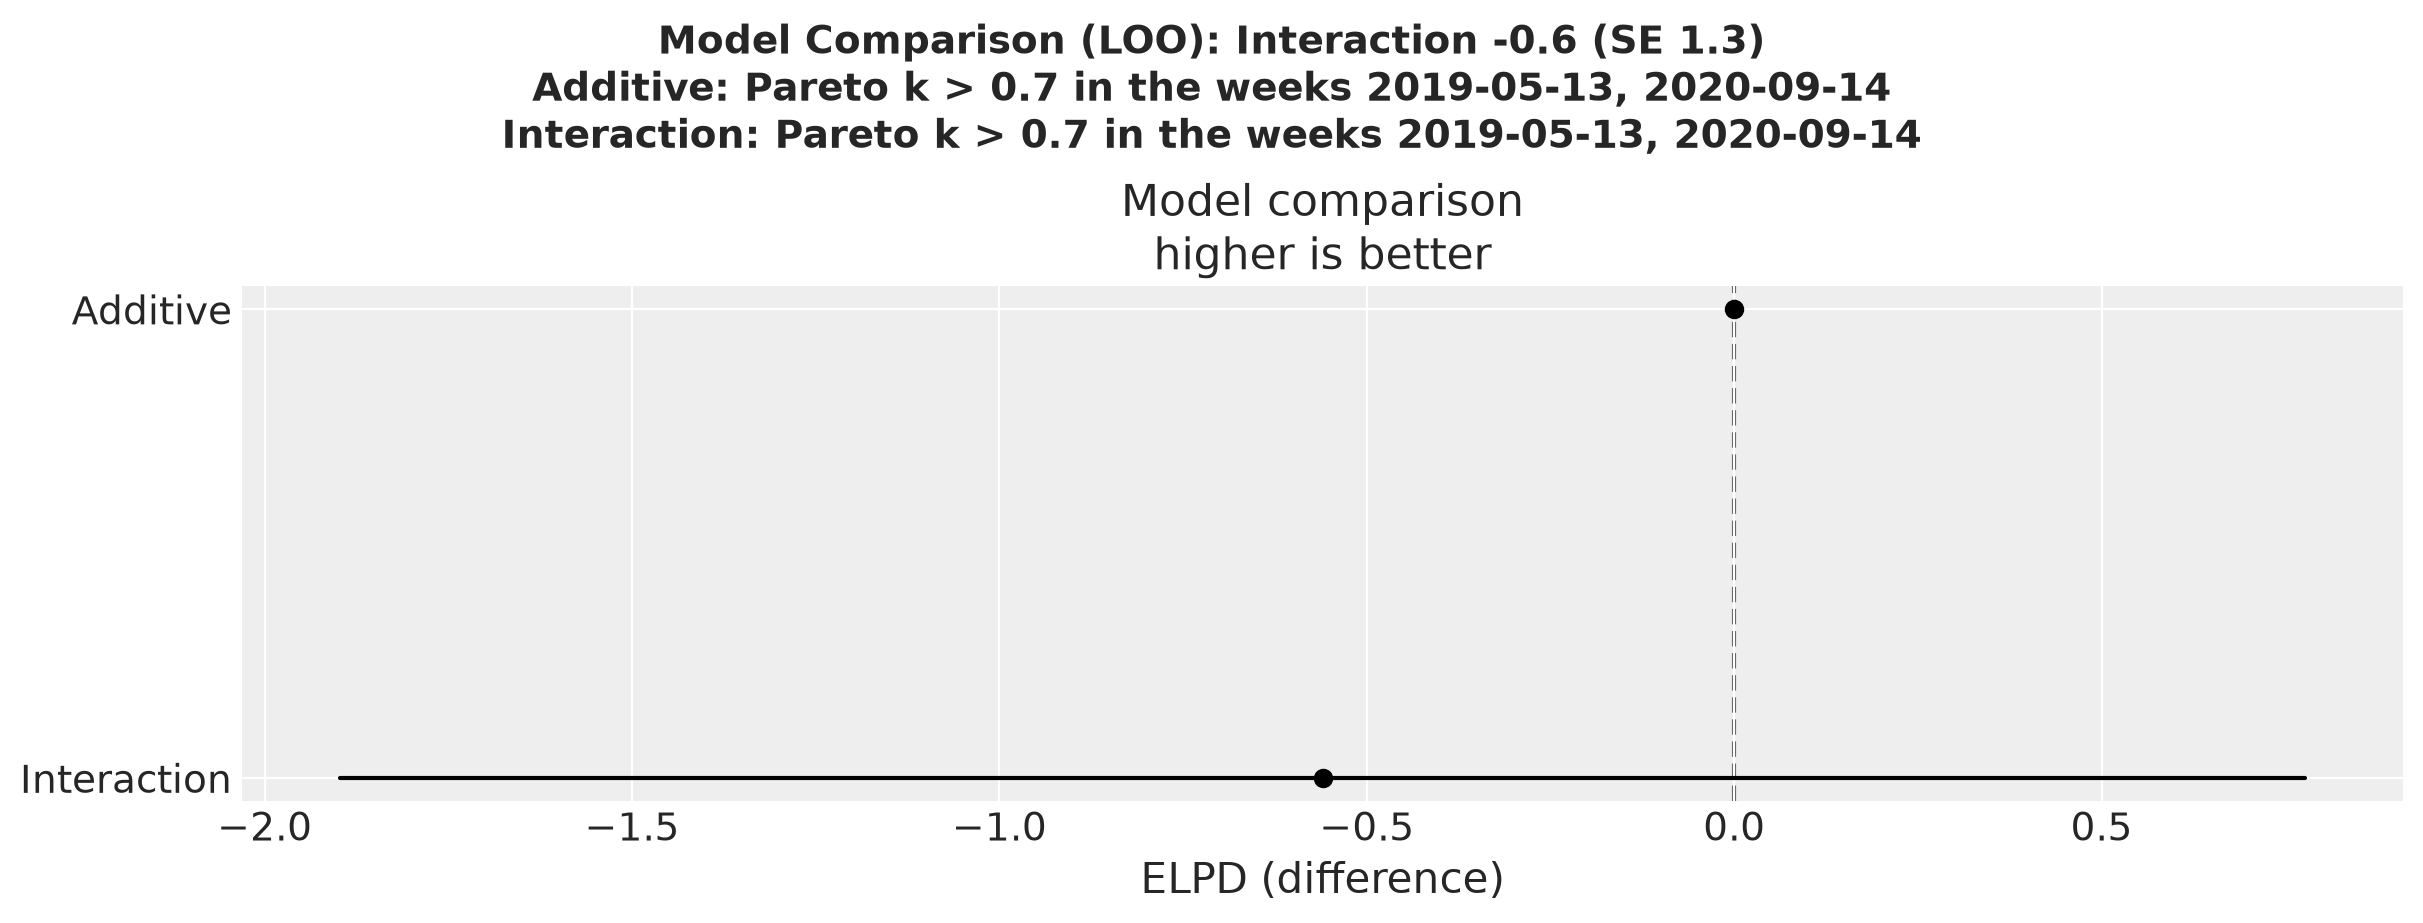

In [37]:
second = comparison.iloc[1]

# Weeks with Pareto k > 0.7, per model
flagged_weeks = {
    name: ", ".join(
        f"{date:%Y-%m-%d}" for date in data.loc[(k > 0.7).to_numpy(), "date_week"]
    )
    for name, k in pareto_k.items()
}

pc = azp.plot_compare(
    comparison, figure_kwargs={"figsize": (12, 4.5), "layout": "constrained"}
)
fig = pc.viz["figure"].item()
fig.suptitle(
    f"Model Comparison (LOO): {second.name} {second['elpd_diff']:+.1f} (SE {second['dse']:.1f})\n"
    + "\n".join(
        f"{name}: Pareto k > 0.7 in the weeks {weeks}"
        for name, weeks in flagged_weeks.items()
    ),
    fontsize=14,
    fontweight="bold",
);

The interaction model is behind the additive model by $0.6$, with a standard error of $1.3$. LOO cannot separate the two models, and the data gives no evidence for the interaction.

```{note}
**Pareto $k$**: Both models flag the same two weeks: the only week with `event_1` and the only week with `event_2`. The model learns each event coefficient from one week, so leaving that week out changes the posterior a lot. These weeks are not related to the interaction, but they make the LOO estimate of both models less reliable.
```

Recall from the Exploratory Data Analysis that `x2` has spend only between about $0.8$ and $1$. The optimal plans spend between $0.010$ and $0.081$ per week on `x2`, levels that we never observed. The model reaches these levels through its functional form, which the data cannot check.

```{warning}
**Critical Assessment**: We tested the interaction effect only on data without synergy, so we do not know if it recovers a synergy that is present in the data when `x2` comes in a few bursts. To check this, simulate the sales with a known interaction term and fit both models again.
```

## Conclusion

We wrote a custom mu effect that adds channel interactions to the additive MMM, and we tested it on data without synergy.

### Key Findings

- **Mu effects**: A mu effect adds a term to $\mu$ through three methods, `create_data`, `create_effect` and `set_data`. An effect that reads `mmm.channel_data_scaled` follows the spend of every budget plan, so the optimizer changes only the spend of `x1` and `x2`.
- **Interaction estimate**: The model estimates a small interaction, and LOO cannot separate it from the additive model. Both models give close ROAS estimates, and their $94\%$ HDIs contain the true ROAS.
- **Budget plan**: Within the guardrails, both models choose the true optimum. Without guardrails, the interaction moves budget to `x2`, and its plan is $0.38\%$ below the true optimum in true incremental sales, against $0.20\%$ for the additive plan.

### Model Limitations

- **Synergy only**: The half-normal prior of $\beta$ allows no cannibalization, and it keeps the estimate above zero.
- **Unobserved spend levels**: `x2` has spend in only $32$ weeks, always at a high level, and the optimal plans spend at levels that we never observed.
- **Same-week product**: The term is the adstock of the product of the spend in the same week. A TV campaign that makes search work better in the weeks after it needs a different form, for example the product of the adstocked spend.

### Recommendations

1. **Add an interaction for a business reason.** Use it when you expect a synergy between specific channels, and check that the data has weeks in which these channels vary independently.
2. **Optimize the full response.** Pass `response_variable="total_response_original_scale"` to the budget optimizer, and compare the plans with and without the interaction.
3. **Report joint totals.** Use the joint incremental sales for a total over channels that interact.

## Next Steps

1. **Funnel effects.** See {ref}`mmm_funnel_mueffect` for a mu effect that models a mediator between upper and lower funnel channels.
2. **Halo and cannibalization.** See {ref}`mmm_halo` for mu effects across products, with a coefficient that can be negative.
3. **Recovery check.** Simulate the sales with a known interaction term and check that the interaction model recovers it. See {ref}`mmm_data_generator` for parameter recovery with simulated data.

In [38]:
%load_ext watermark
%watermark -n -u -v -iv -w -p pymc_marketing,pymc,nutpie

Last updated: Wed, 14 Oct 2026

Python implementation: CPython
Python version       : 3.12.12
IPython version      : 9.15.0

pymc_marketing: 1.2.0
pymc          : 6.3.2
nutpie        : 0.16.11

arviz         : 1.2.0
arviz_plots   : 1.2.0
graphviz      : 0.21
matplotlib    : 3.11.1
numpy         : 2.4.6
pandas        : 3.0.5
pydantic      : 2.13.4
pymc          : 6.3.2
pymc_extras   : 0.15.1
pymc_marketing: 1.2.0
pytensor      : 3.3.2
scipy         : 1.15.3
xarray        : 2026.4.0

Watermark: 2.6.0

